# Team 2 — Master Notebook
### Financial Development and Economic Growth (World Bank WDI, 2004–2021)

**Team 2:** Andrei Piatrouski · Nikita Pasichnyk · Hannes Gantzkow · Jean Yves Nkwane Ebongue  
**Course:** Introduction to Data Analytics, HWR Berlin, SoSe 2026

This notebook combines every team member's analysis into a single document, ordered to match the presentation flow:

1. **SQ1** — Nikita · Mapping the financial landscape
2. **SQ2** — Hannes · Ranking the channels in normal times
3. **SQ5** — Yves · The shift in retail financial access
4. **SQ3 & SQ4** — Andrei · Behaviour through the 2008 and COVID crises

> **How to run:** *Kernel → Restart & Run All.* Each section re-loads the data independently, so the notebook runs top to bottom. Data paths point to `../data` (this notebook lives in `notebooks/`).

---

---

# Part 1 · SQ1 — Mapping the Financial Landscape
**Author: Nikita Pasichnyk**

*Source notebook: `notebooks/sq_1_Nikita/Data_Analysis_SQ1_Financial_Landscape.ipynb`*

---

# SQ1 — Mapping the Financial Landscape

**How do financial profiles differ across income groups, and do the data-driven clusters actually match the World Bank income labels?**

Team 2 · Introduction to Data Analytics, HWR Berlin · SoSe 2026 

This notebook builds the country×year panel from the raw World Bank files and produces the four SQ1 figures (saved to `charts/`). Run the cells top to bottom.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# ── Paths ─────────────────────────────────────────────────────────────────
# DATA_DIR auto-detects whether you run locally (inside the repo) or in Colab.
#   • Local repo layout (notebook two levels under the root) → ../data
#   • Google Colab: upload DataSheet_Main.csv (+ Metadata_Country.csv);
#     they land in /content, which the last candidate below picks up.
_CANDIDATES = [Path("../data"), Path("data"), Path("/content/data"), Path("/content")]
DATA_DIR = next((p for p in _CANDIDATES if (p / "DataSheet_Main.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        "DataSheet_Main.csv not found. In Colab, upload it first "
        "(Files panel on the left, or a files.upload() cell), then run this cell again. "
        "Locally, set DATA_DIR to the folder holding the World Bank CSVs.")
print("Using DATA_DIR =", DATA_DIR)

OUT_DIR = Path("charts")           # figures are saved here, ready for the slides
OUT_DIR.mkdir(exist_ok=True)

# ── Constants ─────────────────────────────────────────────────────────────
CHANNELS      = ["domestic_credit", "broad_money", "bank_branches", "atms", "fdi_inflows"]
INCOME_ORDER  = ["Low income", "Lower middle income", "Upper middle income", "High income"]
CLUSTER_NAMES = ["Cluster 1 (shallow)", "Cluster 2 (medium)",
                 "Cluster 3 (deep)", "Cluster 4 (extreme)"]

# ── SQ1 chart palette (matches the slide deck) ─────────────────────────────
INK, TEAL, ACCENT = "#1d2433", "#2f6f8f", "#c2603f"
SEQ = LinearSegmentedColormap.from_list("seq", ["#eef3f6", "#9cc3d5", "#2f6f8f", "#173f52"])
INCOME_COLORS = {"Low income": "#c2603f", "Lower middle income": "#e0a458",
                 "Upper middle income": "#9cc3d5", "High income": "#2f6f8f"}

plt.rcParams.update({"font.size": 11, "figure.dpi": 120,
                     "axes.spines.top": False, "axes.spines.right": False})

Using DATA_DIR = ../data


## 1 · Load the data and build the panel

Reshape the World Bank files into one row per **country × year**, then attach each country's region and income group. The income label is merged on `Country Code` (canonical) and aggregates like *World* are dropped.

In [2]:
# Indicator code → short name (9 financial indicators; GDP growth comes from the GDP file)
CODE_TO_NAME = {
    "FS.AST.PRVT.GD.ZS":    "domestic_credit",
    "FM.LBL.BMNY.GD.ZS":    "broad_money",
    "FB.CBK.BRCH.P5":       "bank_branches",
    "FB.ATM.TOTL.P5":       "atms",
    "BX.KLT.DINV.WD.GD.ZS": "fdi_inflows",
    "FR.INR.LNDP":          "interest_spread",
    "FB.AST.NPER.ZS":       "nonperforming_loans",
    "CM.MKT.LCAP.GD.ZS":    "market_cap",
    "NY.GDP.DEFL.KD.ZG.AD": "inflation",
    "NY.GDP.MKTP.KD.ZG":    "gdp_growth",    # lives in DataSheet_GDP.csv
}

# World Bank files carry 4 header rows of metadata → skiprows=4
main    = pd.read_csv(DATA_DIR / "DataSheet_Main.csv", skiprows=4, encoding="utf-8-sig")
country = pd.read_csv(DATA_DIR / "Metadata_Country.csv", encoding="utf-8-sig")

# GDP growth sits in a separate, more up-to-date file. SQ1 doesn't use it, but we
# fold it in so this panel matches the team's shared panel.
gdp_path = DATA_DIR / "DataSheet_GDP.csv"
gdp = pd.read_csv(gdp_path, skiprows=4, encoding="utf-8-sig") if gdp_path.exists() else None

# 1) keep only our indicators
fin_codes = [c for c, n in CODE_TO_NAME.items() if n != "gdp_growth"]
frames = [main[main["Indicator Code"].isin(fin_codes)]]
if gdp is not None:
    frames.append(gdp[gdp["Indicator Code"] == "NY.GDP.MKTP.KD.ZG"])
raw = pd.concat(frames, ignore_index=True)

# 2) reshape wide → long → panel (melt, then pivot): one row per country × year
year_cols = [c for c in raw.columns if c.isdigit()]
long = raw.melt(id_vars=["Country Name", "Country Code", "Indicator Code"],
                value_vars=year_cols, var_name="Year", value_name="Value")
long["Year"]  = long["Year"].astype(int)
long["Value"] = pd.to_numeric(long["Value"], errors="coerce")

df_panel = (long.pivot_table(index=["Country Name", "Country Code", "Year"],
                             columns="Indicator Code", values="Value")
                .reset_index()
                .rename(columns=CODE_TO_NAME))
df_panel = df_panel[df_panel["Year"].between(2004, 2021)]

# 3) attach Region + IncomeGroup on the country code, drop aggregates (World etc.)
df_panel = df_panel.merge(country[["Country Code", "Region", "IncomeGroup"]],
                          on="Country Code", how="left")
df_panel = df_panel[df_panel["IncomeGroup"].notna()].copy()
df_panel["IncomeGroup"] = pd.Categorical(df_panel["IncomeGroup"],
                                         categories=INCOME_ORDER, ordered=True)

print("Panel:", df_panel.shape[0], "rows ·", df_panel["Country Name"].nunique(), "countries")
df_panel.head(3)

Panel: 3813 rows · 215 countries


,Country Name,Country Code,Year,fdi_inflows,market_cap,nonperforming_loans,atms,bank_branches,broad_money,interest_spread,domestic_credit,inflation,gdp_growth,Region,IncomeGroup
0,Afghanistan,AFG,2004,3.577104,NaN,NaN,0.02,0.37,NaN,NaN,NaN,11.271432,1.414118,South Asia,Low income
1,Afghanistan,AFG,2005,4.368673,NaN,NaN,0.06,0.58,NaN,NaN,NaN,10.912774,11.229715,South Asia,Low income
2,Afghanistan,AFG,2006,3.413773,NaN,NaN,0.12,0.92,23.343865,NaN,4.842857,7.199751,5.357403,South Asia,Low income


## 2 · Part 1 — Financial profile per income group

The descriptive sanity check: do the financial indicators rise with income? We take the **median** of each indicator per income group — median, not mean, because a few financial hubs would drag the mean up.

In [3]:
# Median financial profile per income group
profile_by_income = df_panel.groupby("IncomeGroup")[CHANNELS].median().reindex(INCOME_ORDER)
profile_by_income.round(1)

,domestic_credit,broad_money,bank_branches,atms,fdi_inflows
IncomeGroup,,,,,
Low income,10.8,22.9,2.2,1.8,2.7
Lower middle income,23.2,39.4,6.3,11.2,2.2
Upper middle income,42.4,49.7,13.2,36.6,3.5
High income,81.8,77.5,23.8,67.6,3.5


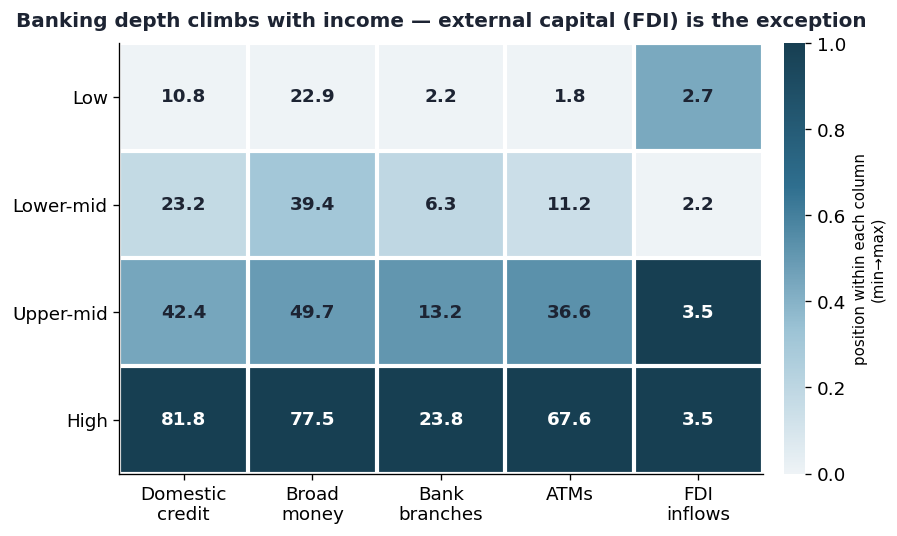

In [4]:
# ── Chart 1 · profile heatmap ──────────────────────────────────────────────
med  = profile_by_income
norm = (med - med.min()) / (med.max() - med.min())     # colour scaled within each column
labels5 = ["Domestic\ncredit", "Broad\nmoney", "Bank\nbranches", "ATMs", "FDI\ninflows"]
short   = ["Low", "Lower-mid", "Upper-mid", "High"]

fig, ax = plt.subplots(figsize=(7.6, 4.6))
im = ax.imshow(norm.values, cmap=SEQ, aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(5)); ax.set_xticklabels(labels5)
ax.set_yticks(range(4)); ax.set_yticklabels(short)
for i in range(4):
    for j in range(5):
        v = med.values[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontweight="bold",
                color="white" if norm.values[i, j] > 0.55 else INK)
ax.set_title("Banking depth climbs with income — external capital (FDI) is the exception",
             fontsize=12, fontweight="bold", pad=10, color=INK)
cb = fig.colorbar(im, ax=ax, fraction=0.045, pad=0.03)
cb.set_label("position within each column\n(min→max)", fontsize=9); cb.outline.set_visible(False)
ax.set_xticks(np.arange(-.5, 5, 1), minor=True); ax.set_yticks(np.arange(-.5, 4, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=2.5); ax.tick_params(which="minor", length=0)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_profile_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

## 3 · Part 2 — Do the data rebuild the income tiers? (clustering)

Hide the income labels and let **k-means** group countries on their financial fingerprint alone. Two deliberate choices: **standardize** first (the indicators are on very different scales) and **k = 4** (to test directly against the four income groups).

In [5]:
# One row per country = its 2004–2021 average on the 5 indicators
profil = df_panel.groupby("Country Name")[CHANNELS].mean()
profil["IncomeGroup"] = (df_panel.drop_duplicates("Country Name")
                                 .set_index("Country Name")["IncomeGroup"])

# Drop countries missing > 2 of 5 indicators (mostly poorer ones — an honest limit),
# then fill the few remaining gaps with the column median so k-means can run.
before = len(profil)
profil = profil[profil[CHANNELS].isna().sum(axis=1) <= 2]
profil[CHANNELS] = profil[CHANNELS].fillna(profil[CHANNELS].median())
print(f"Countries: {before} -> {len(profil)} after dropping sparse rows")

# Standardize (different scales → required) then k-means, k = 4
X  = StandardScaler().fit_transform(profil[CHANNELS])
km = KMeans(n_clusters=4, random_state=0, n_init=10).fit(X)
profil["cluster_id"] = km.labels_

# Relabel clusters by depth: Cluster 1 (shallowest) → Cluster 4 (deepest)
order_by_depth = profil.groupby("cluster_id")["domestic_credit"].mean().sort_values().index
id_to_name = {cid: CLUSTER_NAMES[i] for i, cid in enumerate(order_by_depth)}
profil["cluster"] = pd.Categorical(profil["cluster_id"].map(id_to_name),
                                   categories=CLUSTER_NAMES, ordered=True)

crosstab = pd.crosstab(profil["cluster"], profil["IncomeGroup"]).reindex(CLUSTER_NAMES)[INCOME_ORDER]
print("\nCross-tab (cluster x income):"); print(crosstab)
print("\nMean financial profile per cluster:")
print(profil.groupby("cluster")[CHANNELS].mean().round(1))
print("\nCluster 4 members:",
      sorted(profil.index[profil["cluster"] == CLUSTER_NAMES[3]].tolist()))
print("High-income countries in the shallowest cluster:",
      sorted(profil.index[(profil["cluster"] == CLUSTER_NAMES[0]) &
                          (profil["IncomeGroup"] == "High income")].tolist()))

Countries: 215 -> 186 after dropping sparse rows

Cross-tab (cluster x income):
IncomeGroup          Low income  Lower middle income  Upper middle income  \
cluster                                                                     
Cluster 1 (shallow)          23                   38                   22   
Cluster 2 (medium)            1                   15                   26   
Cluster 3 (deep)              0                    1                    2   
Cluster 4 (extreme)           0                    0                    0   

IncomeGroup          High income  
cluster                           
Cluster 1 (shallow)            2  
Cluster 2 (medium)            39  
Cluster 3 (deep)              15  
Cluster 4 (extreme)            2  

Mean financial profile per cluster:
                     domestic_credit  broad_money  bank_branches   atms  \
cluster                                                                   
Cluster 1 (shallow)             21.0         36.5           

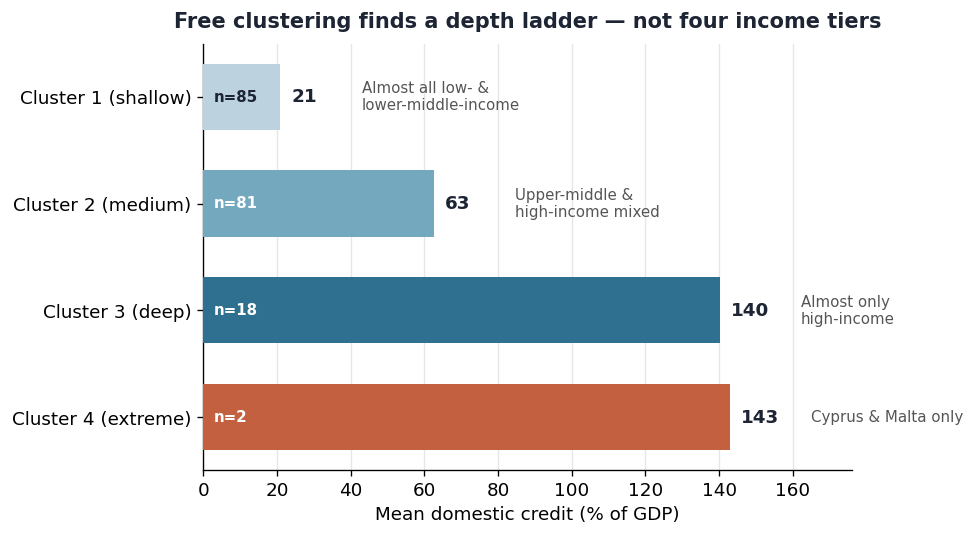

In [6]:
# ── Chart 2 · depth ladder ─────────────────────────────────────────────────
means = profil.groupby("cluster")[CHANNELS].mean().reindex(CLUSTER_NAMES)
sizes = profil["cluster"].value_counts().reindex(CLUSTER_NAMES)
dc    = means["domestic_credit"]
who   = ["Almost all low- &\nlower-middle-income", "Upper-middle &\nhigh-income mixed",
         "Almost only\nhigh-income", "Cyprus & Malta only"]
colors = ["#bcd3df", "#74a8bf", "#2f6f8f", "#c2603f"]

fig, ax = plt.subplots(figsize=(8.2, 4.6)); y = np.arange(4)
ax.barh(y, dc.values, color=colors, height=0.62, zorder=3)
ax.set_yticks(y); ax.set_yticklabels(CLUSTER_NAMES); ax.invert_yaxis()
ax.set_xlabel("Mean domestic credit (% of GDP)"); ax.set_xlim(0, 176)
for i, (v, n, w) in enumerate(zip(dc.values, sizes.values, who)):
    ax.text(v + 3, i, f"{v:.0f}", va="center", fontweight="bold", color=INK)
    ax.text(3, i, f"n={n}", va="center", fontsize=9, fontweight="bold",
            color="white" if v > 40 else INK)
    ax.text(v + 22, i, w, va="center", fontsize=9, color="#555")
ax.set_title("Free clustering finds a depth ladder — not four income tiers",
             fontsize=12.5, fontweight="bold", pad=10, color=INK)
ax.grid(axis="x", color="#e6e6e6", zorder=0)
fig.tight_layout()
fig.savefig(OUT_DIR / "02_depth_ladder.png", dpi=200, bbox_inches="tight")
plt.show()

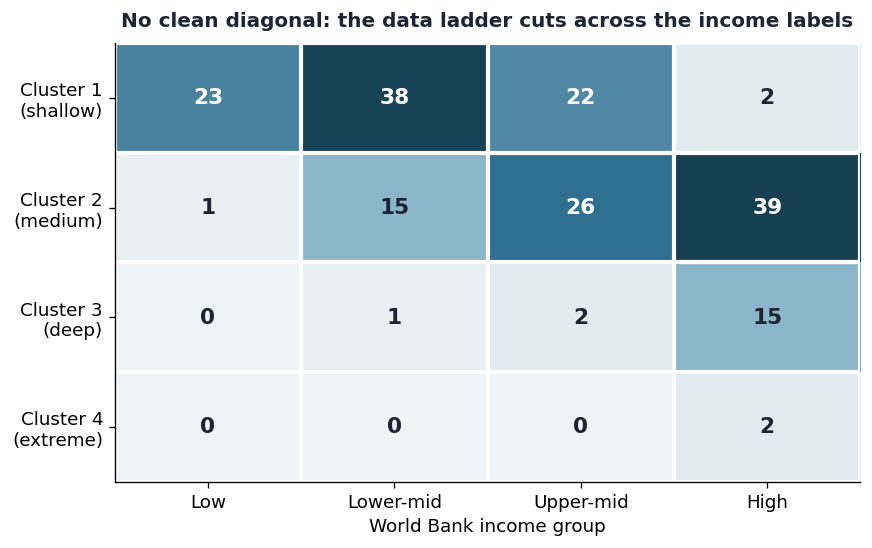

In [7]:
# ── Chart 3 · cluster x income cross-tab ───────────────────────────────────
short_inc     = ["Low", "Lower-mid", "Upper-mid", "High"]
names_wrapped = [n.replace(" (", "\n(") for n in CLUSTER_NAMES]

fig, ax = plt.subplots(figsize=(7.4, 4.7))
im = ax.imshow(crosstab.values, cmap=SEQ, aspect="auto")
ax.set_xticks(range(4)); ax.set_xticklabels(short_inc)
ax.set_yticks(range(4)); ax.set_yticklabels(names_wrapped)
mx = crosstab.values.max()
for i in range(4):
    for j in range(4):
        v = crosstab.values[i, j]
        ax.text(j, i, int(v), ha="center", va="center", fontweight="bold", fontsize=13,
                color="white" if v > mx * 0.5 else INK)
ax.set_xlabel("World Bank income group")
ax.set_title("No clean diagonal: the data ladder cuts across the income labels",
             fontsize=12, fontweight="bold", pad=10, color=INK)
ax.set_xticks(np.arange(-.5, 4, 1), minor=True); ax.set_yticks(np.arange(-.5, 4, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=2.5); ax.tick_params(which="minor", length=0)
fig.tight_layout()
fig.savefig(OUT_DIR / "03_crosstab_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

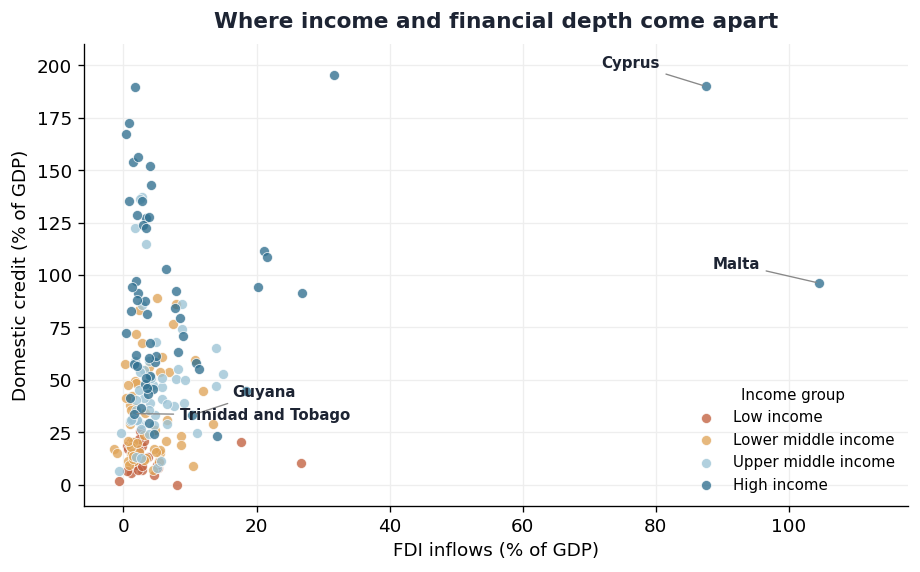

In [8]:
# ── Chart 4 · outliers (FDI vs domestic credit) ────────────────────────────
fig, ax = plt.subplots(figsize=(7.8, 4.9))
for ig in INCOME_ORDER:
    sub = profil[profil["IncomeGroup"] == ig]
    ax.scatter(sub["fdi_inflows"], sub["domestic_credit"], s=36, alpha=0.78,
               color=INCOME_COLORS[ig], label=ig, edgecolor="white", linewidth=0.5, zorder=3)
for name, dx, dy, ha in [("Cyprus", -7, 9, "right"), ("Malta", -9, 7, "right"),
                         ("Guyana", 6, 9, "left"), ("Trinidad and Tobago", 7, -3, "left")]:
    if name in profil.index:
        xv, yv = profil.loc[name, "fdi_inflows"], profil.loc[name, "domestic_credit"]
        ax.annotate(name, (xv, yv), xytext=(xv + dx, yv + dy), fontsize=9, fontweight="bold",
                    color=INK, ha=ha, arrowprops=dict(arrowstyle="-", color="#888", lw=0.8))
ax.set_xlabel("FDI inflows (% of GDP)"); ax.set_ylabel("Domestic credit (% of GDP)")
ax.set_title("Where income and financial depth come apart",
             fontsize=13, fontweight="bold", pad=10, color=INK)
ax.legend(frameon=False, fontsize=9, loc="lower right", title="Income group", title_fontsize=9)
ax.grid(color="#eee", zorder=0); ax.set_xlim(-6, 118); ax.set_ylim(-10, 210)
fig.tight_layout()
fig.savefig(OUT_DIR / "04_outliers_scatter.png", dpi=200, bbox_inches="tight")
plt.show()

## 4 · Takeaways

- **Banking depth climbs with income; FDI is the exception** — it is flat across all four groups.
- Free clustering finds a **ladder of financial depth (≈186 countries), not four income tiers**: the cross-tab drifts the right way but is smeared, not diagonal — upper-middle income splits across three clusters.
- **Outliers:** Cyprus & Malta form their own micro-cluster (FDI ≈ 90–100% of GDP); Guyana & Trinidad and Tobago are high-income but among the shallowest. No low-income country looks financially rich — depth can lag income, never lead it.



---

# Part 2 · SQ2 — Ranking the Channels in Normal Times
**Author: Hannes Gantzkow**

*Source notebook: `notebooks/hannes_sq_2/sq2_v02.ipynb`*

---

In [9]:
print("Which financial indicator — credit, money supply, bank branches, ATMs, or FDI — correlates most strongly with GDP growth in normal times, and does the ranking shift between income groups?")

Which financial indicator — credit, money supply, bank branches, ATMs, or FDI — correlates most strongly with GDP growth in normal times, and does the ranking shift between income groups?


In [10]:
#looking up all variables currently stored in the notebooks memory

%whos

Variable                  Type                       Data/Info
--------------------------------------------------------------
ACCENT                    str                        #c2603f
CHANNELS                  list                       n=5
CLUSTER_NAMES             list                       n=4
CODE_TO_NAME              dict                       n=10
DATA_DIR                  PosixPath                  ../data
INCOME_COLORS             dict                       n=4
INCOME_ORDER              list                       n=4
INK                       str                        #1d2433
KMeans                    ABCMeta                    <class 'sklearn.cluster._kmeans.KMeans'>
LinearSegmentedColormap   type                       <class 'matplotlib.colors<...>LinearSegmentedColormap'>
OUT_DIR                   PosixPath                  charts
Path                      type                       <class 'pathlib.Path'>
SEQ                       LinearSegmentedColormap    <matplotlib.c

In [11]:
#Import libraries needed for SQ2.
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

#Define folders.
DATA_DIR = Path("../data")
PAN_DIR = DATA_DIR / "processed"

#Load the prepared country-year panel.
df_panel = pd.read_csv(PAN_DIR / "financial_panel_2004_2021.csv")

#Load metadata because SQ2 compares results by income group.
country_meta = pd.read_csv(DATA_DIR / "Metadata_Country.csv")

display(df_panel.head())
print(df_panel.shape)
display(country_meta.head())

,Country Name,Year,atms,nonperforming_loans,broad_money,bank_branches,domestic_credit,fdi_inflows,gdp_growth,inflation,interest_spread,market_cap
0,Afghanistan,2004,0.02,NaN,NaN,0.37,NaN,3.577104,1.414118,11.271432,NaN,NaN
1,Afghanistan,2005,0.06,NaN,NaN,0.58,NaN,4.368673,11.229715,10.912774,NaN,NaN
2,Afghanistan,2006,0.12,NaN,23.343865,0.92,4.842857,3.413773,5.357403,7.199751,NaN,NaN
3,Afghanistan,2007,0.21,NaN,23.833664,1.24,6.839982,1.935702,13.826320,22.527756,NaN,NaN
4,Afghanistan,2008,0.30,NaN,29.512281,1.48,9.388328,0.455360,3.924984,2.096289,NaN,NaN


(3831, 12)


,Country Code,Region,IncomeGroup,SpecialNotes,TableName,Unnamed: 5
0,ABW,Latin America & Caribbean,High income,NaN,Aruba,NaN
1,AFE,NaN,NaN,"26 countries, stretching from the Red Sea in t...",Africa Eastern and Southern,NaN
2,AFG,South Asia,Low income,The reporting period for national accounts dat...,Afghanistan,NaN
3,AFW,NaN,NaN,"22 countries, stretching from the westernmost ...",Africa Western and Central,NaN
4,AGO,Sub-Saharan Africa,Lower middle income,The World Bank systematically assesses the app...,Angola,NaN


In [12]:
display(df_panel.head())
print(df_panel.shape)
print(df_panel.columns)
#Count missing values in each column.
#This helps us see which variables have enough data for correlation analysis.
print(df_panel.isna().sum())

,Country Name,Year,atms,nonperforming_loans,broad_money,bank_branches,domestic_credit,fdi_inflows,gdp_growth,inflation,interest_spread,market_cap
0,Afghanistan,2004,0.02,NaN,NaN,0.37,NaN,3.577104,1.414118,11.271432,NaN,NaN
1,Afghanistan,2005,0.06,NaN,NaN,0.58,NaN,4.368673,11.229715,10.912774,NaN,NaN
2,Afghanistan,2006,0.12,NaN,23.343865,0.92,4.842857,3.413773,5.357403,7.199751,NaN,NaN
3,Afghanistan,2007,0.21,NaN,23.833664,1.24,6.839982,1.935702,13.826320,22.527756,NaN,NaN
4,Afghanistan,2008,0.30,NaN,29.512281,1.48,9.388328,0.455360,3.924984,2.096289,NaN,NaN


(3831, 12)
Index(['Country Name', 'Year', 'atms', 'nonperforming_loans', 'broad_money',
       'bank_branches', 'domestic_credit', 'fdi_inflows', 'gdp_growth',
       'inflation', 'interest_spread', 'market_cap'],
      dtype='str')
Country Name              0
Year                      0
atms                    850
nonperforming_loans    1983
broad_money            1029
bank_branches           689
domestic_credit         841
fdi_inflows             367
gdp_growth               79
inflation               117
interest_spread        1650
market_cap             2502
dtype: int64


In [13]:
#Check which country names from the panel do not match the metadata names.
#This helps us identify countries that need manual name fixes before merging.
missing_country_matches = sorted(
    set(df_panel["Country Name"]) - set(country_meta["TableName"])
)

display(missing_country_matches)

["Cote d'Ivoire",
 'Curacao',
 'Puerto Rico (US)',
 'Sao Tome and Principe',
 'Somalia, Fed. Rep.',
 'Turkiye']

In [14]:
display(country_meta.head())

,Country Code,Region,IncomeGroup,SpecialNotes,TableName,Unnamed: 5
0,ABW,Latin America & Caribbean,High income,NaN,Aruba,NaN
1,AFE,NaN,NaN,"26 countries, stretching from the Red Sea in t...",Africa Eastern and Southern,NaN
2,AFG,South Asia,Low income,The reporting period for national accounts dat...,Afghanistan,NaN
3,AFW,NaN,NaN,"22 countries, stretching from the westernmost ...",Africa Western and Central,NaN
4,AGO,Sub-Saharan Africa,Lower middle income,The World Bank systematically assesses the app...,Angola,NaN


In [15]:
#create a seoarate SQ2 working copy
#this keeps the original panel unchanged

df_sq2_base = df_panel.copy()

#create a helper column for merging with the country metadata

df_sq2_base["country_merge_name"] = df_sq2_base["Country Name"]

#Fix country names that differ between df_panel and country_meta.
#These differences would otherwise lead to missing IncomeGroup values.

name_fixes = {
    "Cote d'Ivoire": "Côte d'Ivoire",
    "Curacao": "Curaçao",
    "Sao Tome and Principe": "São Tomé and Principe",
    "Turkiye": "Türkiye",
    "Puerto Rico (US)": "Puerto Rico",
    "Somalia, Fed. Rep.": "Somalia"
}


#Apply the name corrections before merging.
df_sq2_base["country_merge_name"] = df_sq2_base["country_merge_name"].replace(name_fixes)

display(df_sq2_base)

,Country Name,Year,atms,nonperforming_loans,broad_money,bank_branches,domestic_credit,fdi_inflows,gdp_growth,inflation,interest_spread,market_cap,country_merge_name
0,Afghanistan,2004,0.02,NaN,NaN,0.37,NaN,3.577104,1.414118,11.271432,NaN,NaN,Afghanistan
1,Afghanistan,2005,0.06,NaN,NaN,0.58,NaN,4.368673,11.229715,10.912774,NaN,NaN,Afghanistan
2,Afghanistan,2006,0.12,NaN,23.343865,0.92,4.842857,3.413773,5.357403,7.199751,NaN,NaN,Afghanistan
3,Afghanistan,2007,0.21,NaN,23.833664,1.24,6.839982,1.935702,13.826320,22.527756,NaN,NaN,Afghanistan
4,Afghanistan,2008,0.30,NaN,29.512281,1.48,9.388328,0.455360,3.924984,2.096289,NaN,NaN,Afghanistan
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3826,Zimbabwe,2017,6.89,NaN,35.467144,5.64,16.875108,1.746885,4.734411,3.056905,3.640000,NaN,Zimbabwe
3827,Zimbabwe,2018,6.63,NaN,14.379262,5.48,5.830265,2.101721,5.009922,200.769578,4.599167,NaN,Zimbabwe
3828,Zimbabwe,2019,6.40,NaN,16.504433,3.75,5.237706,1.142806,-6.332450,225.394648,13.206667,NaN,Zimbabwe
3829,Zimbabwe,2020,6.16,NaN,14.871527,4.17,5.415074,0.699034,-7.816951,604.945864,28.490000,NaN,Zimbabwe


In [16]:
#Create a small lookup table with only the columns needed for the merge.
#TableName contains the country name used in the World Bank metadata.
#IncomeGroup tells us whether a country is low, middle, or high income.
income_lookup = country_meta[
    ["TableName", "IncomeGroup"]
].copy()

display(income_lookup.head())

,TableName,IncomeGroup
0,Aruba,High income
1,Africa Eastern and Southern,NaN
2,Afghanistan,Low income
3,Africa Western and Central,NaN
4,Angola,Lower middle income


In [17]:
#Create a small lookup table for the income group information.
#We only keep the columns needed for the merge.
income_lookup = country_meta[
    ["TableName", "IncomeGroup"]
].copy()

#Merge the income group into the SQ2 dataset.
#country_merge_name is the corrected country name from df_sq2_base.
#TableName is the country name used in the metadata.
#how="left" keeps all rows from df_sq2_base, even if no match is found.
df_sq2 = df_sq2_base.merge(
    income_lookup,
    left_on="country_merge_name",
    right_on="TableName",
    how="left"
)

display(df_sq2)

,Country Name,Year,atms,nonperforming_loans,broad_money,bank_branches,domestic_credit,fdi_inflows,gdp_growth,inflation,interest_spread,market_cap,country_merge_name,TableName,IncomeGroup
0,Afghanistan,2004,0.02,NaN,NaN,0.37,NaN,3.577104,1.414118,11.271432,NaN,NaN,Afghanistan,Afghanistan,Low income
1,Afghanistan,2005,0.06,NaN,NaN,0.58,NaN,4.368673,11.229715,10.912774,NaN,NaN,Afghanistan,Afghanistan,Low income
2,Afghanistan,2006,0.12,NaN,23.343865,0.92,4.842857,3.413773,5.357403,7.199751,NaN,NaN,Afghanistan,Afghanistan,Low income
3,Afghanistan,2007,0.21,NaN,23.833664,1.24,6.839982,1.935702,13.826320,22.527756,NaN,NaN,Afghanistan,Afghanistan,Low income
4,Afghanistan,2008,0.30,NaN,29.512281,1.48,9.388328,0.455360,3.924984,2.096289,NaN,NaN,Afghanistan,Afghanistan,Low income
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3826,Zimbabwe,2017,6.89,NaN,35.467144,5.64,16.875108,1.746885,4.734411,3.056905,3.640000,NaN,Zimbabwe,Zimbabwe,Lower middle income
3827,Zimbabwe,2018,6.63,NaN,14.379262,5.48,5.830265,2.101721,5.009922,200.769578,4.599167,NaN,Zimbabwe,Zimbabwe,Lower middle income
3828,Zimbabwe,2019,6.40,NaN,16.504433,3.75,5.237706,1.142806,-6.332450,225.394648,13.206667,NaN,Zimbabwe,Zimbabwe,Lower middle income
3829,Zimbabwe,2020,6.16,NaN,14.871527,4.17,5.415074,0.699034,-7.816951,604.945864,28.490000,NaN,Zimbabwe,Zimbabwe,Lower middle income


In [18]:
#Check whether there are still countries without an IncomeGroup after the name fixes.
#These rows did not successfully match with the metadata.

missing_after_fix = (
    df_sq2[df_sq2["IncomeGroup"].isna()]
    [["Country Name", "country_merge_name", "TableName"]]
    .drop_duplicates()
    .sort_values("Country Name")
)

display(missing_after_fix)
print(missing_after_fix.shape)

,Country Name,country_merge_name,TableName
3707,"Venezuela, RB","Venezuela, RB","Venezuela, RB"


(1, 3)


In [19]:
#Remove rows where no IncomeGroup was found.
#These countries cannot be used for the income-group comparison in SQ2.
df_sq2 = df_sq2.dropna(subset=["IncomeGroup"]).copy()
#Remove helper columns that were only needed for the merge.
df_sq2 = df_sq2.drop(columns=["country_merge_name", "TableName"])

In [20]:
display(df_sq2)
print(df_sq2.shape)
print(df_sq2.columns)

,Country Name,Year,atms,nonperforming_loans,broad_money,bank_branches,domestic_credit,fdi_inflows,gdp_growth,inflation,interest_spread,market_cap,IncomeGroup
0,Afghanistan,2004,0.02,NaN,NaN,0.37,NaN,3.577104,1.414118,11.271432,NaN,NaN,Low income
1,Afghanistan,2005,0.06,NaN,NaN,0.58,NaN,4.368673,11.229715,10.912774,NaN,NaN,Low income
2,Afghanistan,2006,0.12,NaN,23.343865,0.92,4.842857,3.413773,5.357403,7.199751,NaN,NaN,Low income
3,Afghanistan,2007,0.21,NaN,23.833664,1.24,6.839982,1.935702,13.826320,22.527756,NaN,NaN,Low income
4,Afghanistan,2008,0.30,NaN,29.512281,1.48,9.388328,0.455360,3.924984,2.096289,NaN,NaN,Low income
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3826,Zimbabwe,2017,6.89,NaN,35.467144,5.64,16.875108,1.746885,4.734411,3.056905,3.640000,NaN,Lower middle income
3827,Zimbabwe,2018,6.63,NaN,14.379262,5.48,5.830265,2.101721,5.009922,200.769578,4.599167,NaN,Lower middle income
3828,Zimbabwe,2019,6.40,NaN,16.504433,3.75,5.237706,1.142806,-6.332450,225.394648,13.206667,NaN,Lower middle income
3829,Zimbabwe,2020,6.16,NaN,14.871527,4.17,5.415074,0.699034,-7.816951,604.945864,28.490000,NaN,Lower middle income


(3813, 13)
Index(['Country Name', 'Year', 'atms', 'nonperforming_loans', 'broad_money',
       'bank_branches', 'domestic_credit', 'fdi_inflows', 'gdp_growth',
       'inflation', 'interest_spread', 'market_cap', 'IncomeGroup'],
      dtype='str')


In [21]:
#Define the target variable for SQ2
#We want to explain or compare financial indicators against GDP growth

target = "gdp_growth"

#These are the five channels whose correlation with GDP growth will be ranked.
financial_indicators = [
    "domestic_credit",
    "broad_money",
    "bank_branches",
    "atms",
    "fdi_inflows"
]

In [22]:
#Select only the columns needed for SQ2.
sq2_data = df_sq2[
    ["Country Name", "Year", "IncomeGroup", target] + financial_indicators
].copy()

display(sq2_data.head())
print(sq2_data.shape)

,Country Name,Year,IncomeGroup,gdp_growth,domestic_credit,broad_money,bank_branches,atms,fdi_inflows
0,Afghanistan,2004,Low income,1.414118,NaN,NaN,0.37,0.02,3.577104
1,Afghanistan,2005,Low income,11.229715,NaN,NaN,0.58,0.06,4.368673
2,Afghanistan,2006,Low income,5.357403,4.842857,23.343865,0.92,0.12,3.413773
3,Afghanistan,2007,Low income,13.826320,6.839982,23.833664,1.24,0.21,1.935702
4,Afghanistan,2008,Low income,3.924984,9.388328,29.512281,1.48,0.30,0.455360


(3813, 9)


In [23]:
#Define crisis years that should be excluded from the "normal times" analysis.
#SQ2 focuses on correlations outside major shocks.
crisis_years = [2008, 2009, 2020, 2021]

#The ~ means "not", so we exclude rows where Year is in crisis_years.
sq2_normal = sq2_data[
    ~sq2_data["Year"].isin(crisis_years)
].copy()

print("Years used:")
print(sorted(sq2_normal["Year"].unique()))

print("Shape after filtering normal times:")
print(sq2_normal.shape)

Years used:
[np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019)]
Shape after filtering normal times:
(2969, 9)


In [24]:

#Create a missing-value overview for the SQ2 normal-times dataset.
#This shows both the number and percentage of missing values per column.
missing_overview = pd.DataFrame({
    "missing_values": sq2_normal.isna().sum(),
    "missing_percent": (sq2_normal.isna().mean() * 100).round(2)
})

display(missing_overview)

,missing_values,missing_percent
Country Name,0,0.00
Year,0,0.00
IncomeGroup,0,0.00
gdp_growth,66,2.22
domestic_credit,638,21.49
broad_money,776,26.14
bank_branches,519,17.48
atms,649,21.86
fdi_inflows,283,9.53


In [25]:
#Create an empty list to store one correlation result per income group and indicator
group_correlations = []

#Loop through each income group separately.
for income_group, group_data in sq2_normal.groupby("IncomeGroup"):

    #For each income group, calculate the correlation for each financial indicator.
    for indicator in financial_indicators:
        #Keep only the current financial indicator and GDP growth.
        #dropna() removes rows where either value is missing, because correlation can only be calculated with complete pairs.
        temp = group_data[[indicator, target]].dropna()
        #Calculate the correlation between the financial indicator and GDP growth.
        #Positive values mean that higher indicator values tend to move together with higher GDP growth.
        #Negative values mean that higher indicator values tend to move together with lower GDP growth.
        correlation = temp[indicator].corr(temp[target])

        #Store the result as one row in our output table.
        group_correlations.append({
            "IncomeGroup": income_group,
            "indicator": indicator,
            "correlation_with_gdp_growth": correlation,
            "abs_correlation": abs(correlation),
            "number_of_observations": len(temp)
        })
#Convert the list of results into a DataFrame.
group_corr_df = pd.DataFrame(group_correlations)

display(group_corr_df)

,IncomeGroup,indicator,correlation_with_gdp_growth,abs_correlation,number_of_observations
0,High income,domestic_credit,-0.215377,0.215377,744
1,High income,broad_money,-0.086404,0.086404,497
2,High income,bank_branches,-0.127734,0.127734,780
3,High income,atms,-0.115132,0.115132,778
4,High income,fdi_inflows,0.001292,0.001292,881
5,Low income,domestic_credit,0.044972,0.044972,286
6,Low income,broad_money,-0.061523,0.061523,290
7,Low income,bank_branches,-0.053957,0.053957,282
8,Low income,atms,-0.123871,0.123871,235
9,Low income,fdi_inflows,0.123136,0.123136,309


In [26]:
#Sort the correlation results within each income group.
#The strongest correlations appear first because we sort by abs_correlation descending.
group_ranking = group_corr_df.sort_values(
    ["IncomeGroup", "abs_correlation"],
    ascending=[True, False]
).copy()

display(group_ranking)

,IncomeGroup,indicator,correlation_with_gdp_growth,abs_correlation,number_of_observations
0,High income,domestic_credit,-0.215377,0.215377,744
2,High income,bank_branches,-0.127734,0.127734,780
3,High income,atms,-0.115132,0.115132,778
1,High income,broad_money,-0.086404,0.086404,497
4,High income,fdi_inflows,0.001292,0.001292,881
8,Low income,atms,-0.123871,0.123871,235
9,Low income,fdi_inflows,0.123136,0.123136,309
6,Low income,broad_money,-0.061523,0.061523,290
7,Low income,bank_branches,-0.053957,0.053957,282
5,Low income,domestic_credit,0.044972,0.044972,286


In [27]:
# Create a clean display table for the SQ2 ranking.
group_ranking_display = group_ranking[
    [
        "IncomeGroup",
        "indicator",
        "correlation_with_gdp_growth",
        "abs_correlation",
        "number_of_observations"
    ]
].copy()

#Round the correlation values to make the table easier to read.
group_ranking_display["correlation_with_gdp_growth"] = (
    group_ranking_display["correlation_with_gdp_growth"].round(3)
)

group_ranking_display["abs_correlation"] = (
    group_ranking_display["abs_correlation"].round(3)
)

display(group_ranking_display)

,IncomeGroup,indicator,correlation_with_gdp_growth,abs_correlation,number_of_observations
0,High income,domestic_credit,-0.215,0.215,744
2,High income,bank_branches,-0.128,0.128,780
3,High income,atms,-0.115,0.115,778
1,High income,broad_money,-0.086,0.086,497
4,High income,fdi_inflows,0.001,0.001,881
8,Low income,atms,-0.124,0.124,235
9,Low income,fdi_inflows,0.123,0.123,309
6,Low income,broad_money,-0.062,0.062,290
7,Low income,bank_branches,-0.054,0.054,282
5,Low income,domestic_credit,0.045,0.045,286


In [28]:
#Keep only the strongest financial indicator per income group.
#This works because group_ranking_display is already sorted by IncomeGroup and abs_correlation from strongest to weakest.
top_indicators = group_ranking_display.groupby("IncomeGroup").head(1)

display(top_indicators)

,IncomeGroup,indicator,correlation_with_gdp_growth,abs_correlation,number_of_observations
0,High income,domestic_credit,-0.215,0.215,744
8,Low income,atms,-0.124,0.124,235
13,Lower middle income,atms,-0.229,0.229,629
18,Upper middle income,atms,-0.131,0.131,663


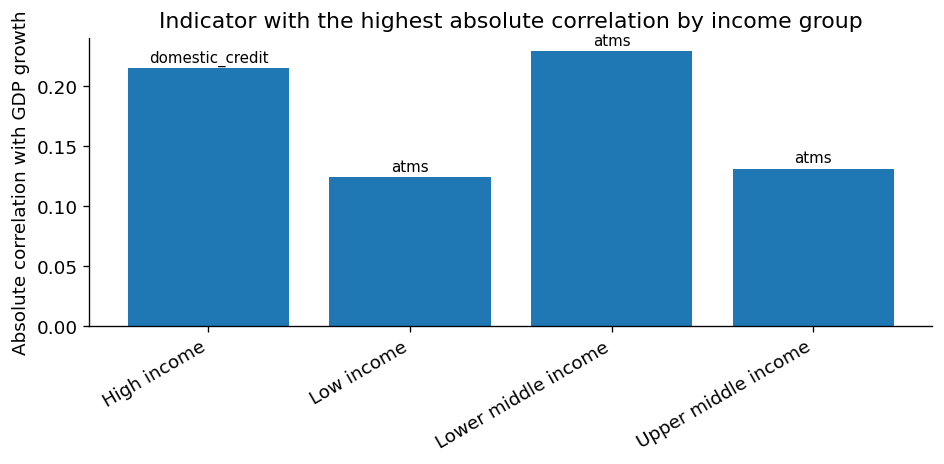

In [29]:
#Create a bar chart showing the strongest correlation per income group.
plt.figure(figsize=(8, 4))

plt.bar(
    top_indicators["IncomeGroup"],
    top_indicators["abs_correlation"]
)

#Rotate x-axis labels so they are easier to read.
plt.xticks(rotation=30, ha="right")
plt.ylabel("Absolute correlation with GDP growth")
plt.title("Indicator with the highest absolute correlation by income group")

#Add the indicator name above each bar.
for index, row in top_indicators.iterrows():
    plt.text(
        x=list(top_indicators.index).index(index),
        y=row["abs_correlation"] + 0.005,
        s=row["indicator"],   # changed from indicator_label to indicator
        ha="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [30]:
#Reshape the correlation results into a matrix.
#Rows are income groups, columns are financial indicators and the values are the correlations with GDP growth.
corr_matrix = group_corr_df.pivot(
    index="IncomeGroup",
    columns="indicator",
    values="correlation_with_gdp_growth"
)

display(corr_matrix.round(3))

indicator,atms,bank_branches,broad_money,domestic_credit,fdi_inflows
IncomeGroup,,,,,
High income,-0.115,-0.128,-0.086,-0.215,0.001
Low income,-0.124,-0.054,-0.062,0.045,0.123
Lower middle income,-0.229,0.034,-0.061,-0.041,0.141
Upper middle income,-0.131,-0.071,-0.069,-0.033,0.081


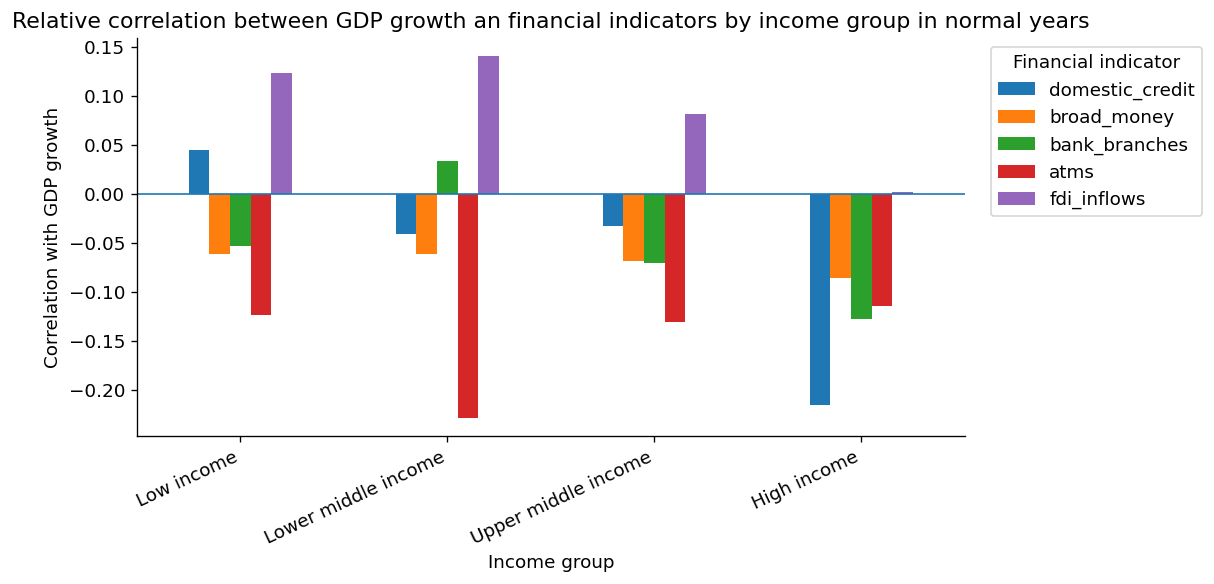

In [31]:
#Prepare the matrix for the plot.
# Rows are income groups, columns are financial indicators, and values are signed correlations with GDP growth.
plot_data_signed = group_corr_df.pivot(
    index="IncomeGroup",
    columns="indicator",
    values="correlation_with_gdp_growth"
)

#Set the order of income groups in the chart.
income_order = [
    "Low income",
    "Lower middle income",
    "Upper middle income",
    "High income"
]

#Set the order of indicators using the original column names.
indicator_order = [
    "domestic_credit",
    "broad_money",
    "bank_branches",
    "atms",
    "fdi_inflows"
]

#Apply the selected row and column order.
plot_data_signed = plot_data_signed.loc[income_order, indicator_order]

#Create a grouped bar chart with signed correlations.
ax = plot_data_signed.plot(
    kind="bar",
    figsize=(10, 5)
)

#Add a zero line so positive and negative correlations are easy to compare.
plt.axhline(0, linewidth=1)

plt.ylabel("Correlation with GDP growth")
plt.xlabel("Income group")
plt.title("Relative correlation between GDP growth an financial indicators by income group in normal years")
plt.xticks(rotation=25, ha="right")
plt.legend(title="Financial indicator", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [32]:
#Calculate median values of the financial indicators by year and income group.
#The median is used because it is less affected by extreme outliers than the mean.
indicator_trends = (
    df_sq2
    .dropna(subset=["Year", "IncomeGroup"])
    .groupby(["Year", "IncomeGroup"])[financial_indicators]
    .median()
    .reset_index()
)

#Keep only the project period from 2004 to 2021.
indicator_trends = indicator_trends[
    (indicator_trends["Year"] >= 2004) & 
    (indicator_trends["Year"] <= 2021)
].copy()

#Make sure Year is stored as an integer.
#This helps with sorting and plotting time trends.
indicator_trends["Year"] = indicator_trends["Year"].astype(int)


display(indicator_trends.head())

,Year,IncomeGroup,domestic_credit,broad_money,bank_branches,atms,fdi_inflows
0,2004,High income,67.268326,71.825797,27.825,59.040,3.793092
1,2004,Low income,7.160592,18.233091,1.120,0.040,2.173354
2,2004,Lower middle income,17.047785,32.915034,4.730,2.125,1.594525
3,2004,Upper middle income,23.379183,40.454432,10.750,17.535,3.495757
4,2005,High income,72.384880,69.573753,26.590,60.505,4.951054


In [33]:
#Create a copy of the trend dataset.
percent_change_trends = indicator_trends.copy()

#Calculate the percentage change since 2004 for each financial indicator.
#This is necessary because of different units between indicators.
for indicator in financial_indicators:
    
    #Get the 2004 baseline value for each income group.
    #This is the starting point for the percentage change calculation.
    base_2004 = (
        percent_change_trends[percent_change_trends["Year"] == 2004]
        [["IncomeGroup", indicator]]
        .rename(columns={indicator: f"{indicator}_base_2004"})
    )
    
    #Add the 2004 baseline value back to every year of the same income group.
    percent_change_trends = percent_change_trends.merge(
        base_2004,
        on="IncomeGroup",
        how="left"
    )
    
    #Calculate how much the indicator changed compared to 2004.
    #Example: 50 means the value is 50% higher than in 2004.
    percent_change_trends[f"{indicator}_pct_change"] = (
        (percent_change_trends[indicator] - percent_change_trends[f"{indicator}_base_2004"])
        / percent_change_trends[f"{indicator}_base_2004"] * 100
    )

display(percent_change_trends.head())

,Year,IncomeGroup,domestic_credit,broad_money,bank_branches,atms,fdi_inflows,domestic_credit_base_2004,domestic_credit_pct_change,broad_money_base_2004,broad_money_pct_change,bank_branches_base_2004,bank_branches_pct_change,atms_base_2004,atms_pct_change,fdi_inflows_base_2004,fdi_inflows_pct_change
0,2004,High income,67.268326,71.825797,27.825,59.040,3.793092,67.268326,0.000000,71.825797,0.000000,27.825,0.000000,59.040,0.000000,3.793092,0.000000
1,2004,Low income,7.160592,18.233091,1.120,0.040,2.173354,7.160592,0.000000,18.233091,0.000000,1.120,0.000000,0.040,0.000000,2.173354,0.000000
2,2004,Lower middle income,17.047785,32.915034,4.730,2.125,1.594525,17.047785,0.000000,32.915034,0.000000,4.730,0.000000,2.125,0.000000,1.594525,0.000000
3,2004,Upper middle income,23.379183,40.454432,10.750,17.535,3.495757,23.379183,0.000000,40.454432,0.000000,10.750,0.000000,17.535,0.000000,3.495757,0.000000
4,2005,High income,72.384880,69.573753,26.590,60.505,4.951054,67.268326,7.606185,71.825797,-3.135424,27.825,-4.438455,59.040,2.481369,3.793092,30.528202


In [34]:
#Import plotting tools.
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

#Define the financial indicators used for the trend plots.
financial_indicators = [
    "domestic_credit",
    "broad_money",
    "bank_branches",
    "atms",
    "fdi_inflows"
]

#Add GDP growth to the list of variables we want to plot over time.
all_trend_variables = financial_indicators + ["gdp_growth"]

#Define a fixed order for income groups.
#This keeps plots consistent and easier to compare.
income_order = [
    "Low income",
    "Lower middle income",
    "Upper middle income",
    "High income"
]

#Define one color per income group.
#This keeps the same group visually consistent across all plots.
income_colors = {
    "Low income": "tab:blue",
    "Lower middle income": "tab:orange",
    "Upper middle income": "tab:green",
    "High income": "tab:red"
}

In [35]:
#Calculate median values by year and income group.
#This prepares trend data for all financial indicators and GDP growth.
trend_data = (
    df_sq2
    .dropna(subset=["Year", "IncomeGroup"])
    .groupby(["Year", "IncomeGroup"])[all_trend_variables]
    .median()
    .reset_index()
)

#Keep only the project period from 2004 to 2021.
trend_data = trend_data[
    (trend_data["Year"] >= 2004) &
    (trend_data["Year"] <= 2021)
].copy()

#Make sure Year is stored as an integer for plotting.
trend_data["Year"] = trend_data["Year"].astype(int)

display(trend_data.head())

,Year,IncomeGroup,domestic_credit,broad_money,bank_branches,atms,fdi_inflows,gdp_growth
0,2004,High income,67.268326,71.825797,27.825,59.040,3.793092,4.218941
1,2004,Low income,7.160592,18.233091,1.120,0.040,2.173354,5.338751
2,2004,Lower middle income,17.047785,32.915034,4.730,2.125,1.594525,5.239533
3,2004,Upper middle income,23.379183,40.454432,10.750,17.535,3.495757,5.300000
4,2005,High income,72.384880,69.573753,26.590,60.505,4.951054,3.485309


In [36]:
#Create a copy of the yearly median trend data.
#We use this copy for the percentage-change plot.
trend_plot_data = trend_data.copy()

#Calculate percentage change since 2004 for each financial indicator.
for indicator in financial_indicators:
    
    #Get the 2004 value for each income group.
    #This becomes the baseline for the percentage change.
    base_2004 = (
        trend_plot_data[trend_plot_data["Year"] == 2004]
        [["IncomeGroup", indicator]]
        .rename(columns={indicator: f"{indicator}_base_2004"})
    )
    
    #Add the 2004 baseline value to all years of the same income group.
    trend_plot_data = trend_plot_data.merge(
        base_2004,
        on="IncomeGroup",
        how="left"
    )
    
    #Calculate the percentage change compared to 2004.
    trend_plot_data[f"{indicator}_pct_change"] = (
        (trend_plot_data[indicator] - trend_plot_data[f"{indicator}_base_2004"])
        / trend_plot_data[f"{indicator}_base_2004"] * 100
    )

In [37]:
#Define crisis years that should be excluded from the normal-years trend analysis.
#This keeps the trend plot consistent with the SQ2 correlation analysis.
crisis_years = [2008, 2009, 2020, 2021]

#Calculate median values by year and income group.
#We use the median to reduce the influence of extreme country values.
trend_data = (
    df_sq2
    .dropna(subset=["Year", "IncomeGroup"])
    .groupby(["Year", "IncomeGroup"])[all_trend_variables]
    .median()
    .reset_index()
)

#Keep only the project period and remove crisis years.
trend_data = trend_data[
    (trend_data["Year"] >= 2004) &
    (trend_data["Year"] <= 2021) &
    (~trend_data["Year"].isin(crisis_years))
].copy()

#Make sure Year is stored as an integer for sorting and plotting.
trend_data["Year"] = trend_data["Year"].astype(int)

#Create a copy for the plot data.
#This copy will include percentage-change columns.
trend_plot_data = trend_data.copy()

#Calculate percentage change since 2004 for each financial indicator.
for indicator in financial_indicators:
    
    #Get the 2004 baseline value for each income group.
    base_2004 = (
        trend_plot_data[trend_plot_data["Year"] == 2004]
        [["IncomeGroup", indicator]]
        .rename(columns={indicator: f"{indicator}_base_2004"})
    )
    
    #Add the 2004 baseline value to all years of the same income group.
    trend_plot_data = trend_plot_data.merge(
        base_2004,
        on="IncomeGroup",
        how="left"
    )
    
    #Calculate the percentage change compared to 2004.
    trend_plot_data[f"{indicator}_pct_change"] = (
        (trend_plot_data[indicator] - trend_plot_data[f"{indicator}_base_2004"])
        / trend_plot_data[f"{indicator}_base_2004"] * 100
    )

#Get the 2004 GDP growth value for each income group.
#GDP growth is already a percentage rate, so we calculate percentage-point change, not percent change.
base_gdp_2004 = (
    trend_plot_data[trend_plot_data["Year"] == 2004]
    [["IncomeGroup", "gdp_growth"]]
    .rename(columns={"gdp_growth": "gdp_growth_base_2004"})
)

#Add the 2004 GDP growth baseline to all years of the same income group.
trend_plot_data = trend_plot_data.merge(
    base_gdp_2004,
    on="IncomeGroup",
    how="left"
)

#Calculate change in GDP growth compared to 2004.
#Example: +2 means GDP growth is 2 percentage points higher than in 2004.
trend_plot_data["gdp_growth_change_since_2004"] = (
    trend_plot_data["gdp_growth"] - trend_plot_data["gdp_growth_base_2004"]
)

#Check the prepared plot data and confirm which years are used.
display(trend_plot_data.head())
print("Years used:", sorted(trend_plot_data["Year"].unique()))

,Year,IncomeGroup,domestic_credit,broad_money,bank_branches,atms,fdi_inflows,gdp_growth,domestic_credit_base_2004,domestic_credit_pct_change,broad_money_base_2004,broad_money_pct_change,bank_branches_base_2004,bank_branches_pct_change,atms_base_2004,atms_pct_change,fdi_inflows_base_2004,fdi_inflows_pct_change,gdp_growth_base_2004,gdp_growth_change_since_2004
0,2004,High income,67.268326,71.825797,27.825,59.040,3.793092,4.218941,67.268326,0.000000,71.825797,0.000000,27.825,0.000000,59.040,0.000000,3.793092,0.000000,4.218941,0.000000
1,2004,Low income,7.160592,18.233091,1.120,0.040,2.173354,5.338751,7.160592,0.000000,18.233091,0.000000,1.120,0.000000,0.040,0.000000,2.173354,0.000000,5.338751,0.000000
2,2004,Lower middle income,17.047785,32.915034,4.730,2.125,1.594525,5.239533,17.047785,0.000000,32.915034,0.000000,4.730,0.000000,2.125,0.000000,1.594525,0.000000,5.239533,0.000000
3,2004,Upper middle income,23.379183,40.454432,10.750,17.535,3.495757,5.300000,23.379183,0.000000,40.454432,0.000000,10.750,0.000000,17.535,0.000000,3.495757,0.000000,5.300000,0.000000
4,2005,High income,72.384880,69.573753,26.590,60.505,4.951054,3.485309,67.268326,7.606185,71.825797,-3.135424,27.825,-4.438455,59.040,2.481369,3.793092,30.528202,4.218941,-0.733632


Years used: [np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019)]


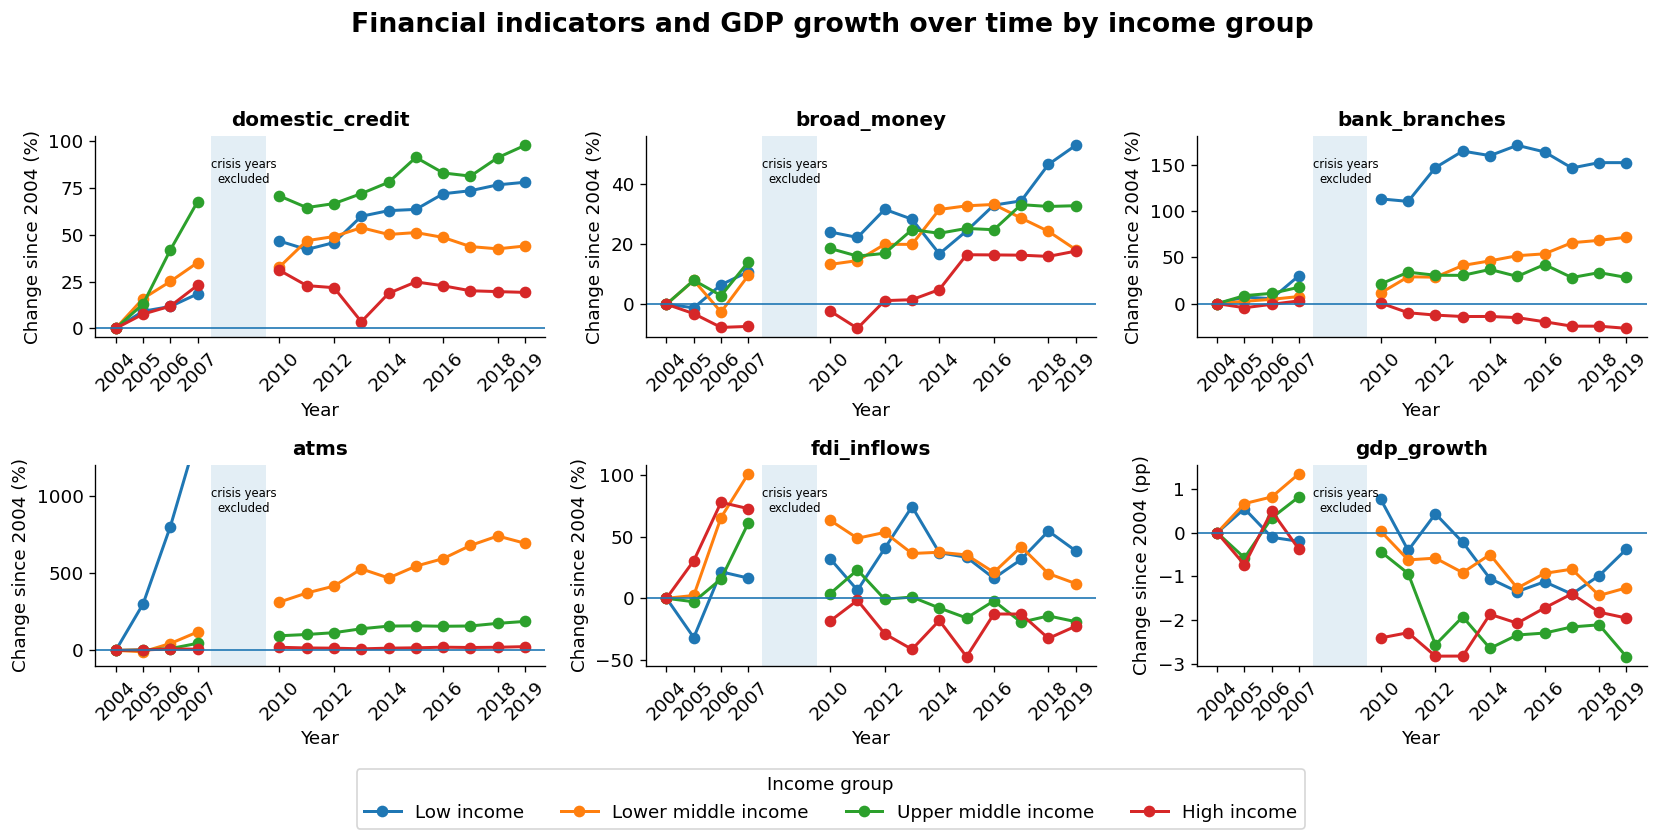

In [38]:
#Create a 2x3 plot layout.
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(14, 7),
    sharex=False
)

#Flatten the axes so we can loop through them more easily.
axes = axes.flatten()

#Define x-axis ticks for the normal years shown in the plot.
year_ticks = [2004, 2005, 2006, 2007, 2010, 2012, 2014, 2016, 2018, 2019]

#Define normal-year blocks.
#Splitting the years prevents lines from connecting across excluded crisis years.
normal_year_blocks = [
    list(range(2004, 2008)),
    list(range(2010, 2020))
]

#Plot the five financial indicators.
for ax, indicator in zip(axes[:5], financial_indicators):
    
    #Plot one line per income group.
    for income_group in income_order:
        subset_all = trend_plot_data[
            trend_plot_data["IncomeGroup"] == income_group
        ].sort_values("Year")
        
        #Plot each normal-year block separately.
        for block_id, year_block in enumerate(normal_year_blocks):
            subset = subset_all[
                subset_all["Year"].isin(year_block)
            ]
            
            ax.plot(
                subset["Year"],
                subset[f"{indicator}_pct_change"],
                marker="o",
                linewidth=1.8,
                color=income_colors[income_group],
                label=income_group if block_id == 0 else None
            )
    
    #Add baseline and labels.
    ax.axhline(0, linewidth=1)
    ax.set_title(indicator, fontsize=12, fontweight="bold")
    ax.set_ylabel("Change since 2004 (%)")
    ax.set_xlabel("Year")
    ax.set_xticks(year_ticks)
    ax.xaxis.set_major_locator(mticker.FixedLocator(year_ticks))
    ax.xaxis.set_major_formatter(mticker.FormatStrFormatter("%d"))
    ax.tick_params(axis="x", rotation=45)
    
    #Mark the excluded 2008–2009 crisis period.
    ax.axvspan(2007.5, 2009.5, alpha=0.12)
    ax.text(
        0.33, 0.82,
        "crisis years\nexcluded",
        transform=ax.transAxes,
        ha="center",
        va="center",
        fontsize=7
    )
    
    #Limit the ATM panel because low-income ATM growth becomes very large due to a very small 2004 baseline.
    if indicator == "atms":
        ax.set_ylim(-100, 1200)

#Plot GDP growth in the sixth panel.
ax = axes[5]

for income_group in income_order:
    subset_all = trend_plot_data[
        trend_plot_data["IncomeGroup"] == income_group
    ].sort_values("Year")
    
    for block_id, year_block in enumerate(normal_year_blocks):
        subset = subset_all[
            subset_all["Year"].isin(year_block)
        ]
        
        ax.plot(
            subset["Year"],
            subset["gdp_growth_change_since_2004"],
            marker="o",
            linewidth=1.8,
            color=income_colors[income_group],
            label=income_group if block_id == 0 else None
        )

ax.axhline(0, linewidth=1)
ax.set_title("gdp_growth", fontsize=12, fontweight="bold")
ax.set_ylabel("Change since 2004 (pp)")
ax.set_xlabel("Year")
ax.set_xticks(year_ticks)
ax.xaxis.set_major_locator(mticker.FixedLocator(year_ticks))
ax.xaxis.set_major_formatter(mticker.FormatStrFormatter("%d"))
ax.tick_params(axis="x", rotation=45)

# Mark the excluded 2008–2009 crisis period.
ax.axvspan(2007.5, 2009.5, alpha=0.12)
ax.text(
    0.33, 0.82,
    "crisis years\nexcluded",
    transform=ax.transAxes,
    ha="center",
    va="center",
    fontsize=7
)

#Create one shared legend for all panels.
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    title="Income group",
    loc="lower center",
    ncol=4,
    frameon=True
)

fig.suptitle(
    "Financial indicators and GDP growth over time by income group",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0.08, 1, 0.94])
plt.show()

---

# Part 3 · SQ5 — The Shift in Retail Financial Access
**Author: Jean Yves Nkwane Ebongue**

*Source notebook: `notebooks/yves_sq_5/sq5.ipynb`*

---

# SQ5 — The Shift in Retail Financial Access

**Research question:** How has the balance between physical bank branches and ATM networks evolved across income groups between 2004 and 2021, and to what degree does the speed of this shift track GDP growth performance in lower- and lower-middle-income economies?

**Why it matters:** SQ2–SQ4 treat finance largely as a stock (depth, access at a point in time). SQ5 adds the **structural-change angle**: financial access itself is being reshaped during our observation window. The policy debate today is precisely about whether that reshaping is helping or just substituting.

**Approach:**
1. Time series of branches per 100k adults and ATMs per 100k adults, broken down by income group and region
2. Identification of countries with the fastest substitution from branches to ATMs
3. Pairing the substitution speed against GDP growth within lower-income economies

**Key indicators:**
- `FB.ATM.TOTL.P5` — Automated teller machines (ATMs) per 100,000 adults
- `FB.CBK.BRCH.P5` — Commercial bank branches per 100,000 adults
- `NY.GDP.MKTP.KD.ZG` — GDP growth (annual %)

**Data sources:** World Development Indicators (WDI), IMF Financial Access Survey

## 1 — Setup & Data Loading

In [39]:
# ══════════════════════════════════════════════════════════════════════
# Import all required libraries
# ══════════════════════════════════════════════════════════════════════
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')  # Suppress warnings to keep output clean

# ── Global plotting settings ──
# Set consistent size, resolution and style so every chart
# in this notebook has the same professional look.
plt.rcParams.update({
    'figure.figsize': (14, 6),
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.dpi': 120
})
sns.set_style('whitegrid')  # White background with light gridlines

print('Libraries loaded successfully.')

Libraries loaded successfully.


In [40]:
# ── Load the pre-processed panel ──
# This CSV was created by the data_overview_plus_merging.ipynb notebook.
# It already contains the 10 financial indicators as columns,
# with one row per country per year (2004–2021).
DATA_DIR = '../data/'

panel = pd.read_csv(DATA_DIR + 'processed/financial_panel_2004_2021.csv')

# Quick summary to verify the data loaded correctly
print(f'Panel shape: {panel.shape}')
print(f'Columns: {panel.columns.tolist()}')
print(f'Year range: {panel["Year"].min()} – {panel["Year"].max()}')
print(f'Countries: {panel["Country Name"].nunique()}')
panel.head()

Panel shape: (3831, 12)
Columns: ['Country Name', 'Year', 'atms', 'nonperforming_loans', 'broad_money', 'bank_branches', 'domestic_credit', 'fdi_inflows', 'gdp_growth', 'inflation', 'interest_spread', 'market_cap']
Year range: 2004 – 2021
Countries: 216


,Country Name,Year,atms,nonperforming_loans,broad_money,bank_branches,domestic_credit,fdi_inflows,gdp_growth,inflation,interest_spread,market_cap
0,Afghanistan,2004,0.02,NaN,NaN,0.37,NaN,3.577104,1.414118,11.271432,NaN,NaN
1,Afghanistan,2005,0.06,NaN,NaN,0.58,NaN,4.368673,11.229715,10.912774,NaN,NaN
2,Afghanistan,2006,0.12,NaN,23.343865,0.92,4.842857,3.413773,5.357403,7.199751,NaN,NaN
3,Afghanistan,2007,0.21,NaN,23.833664,1.24,6.839982,1.935702,13.826320,22.527756,NaN,NaN
4,Afghanistan,2008,0.30,NaN,29.512281,1.48,9.388328,0.455360,3.924984,2.096289,NaN,NaN


In [41]:
# ── Load country metadata for income group & region classification ──
# This file maps each country to its geographic region and income group
# (Low income, Lower middle, Upper middle, High income).
# We filter to keep only actual countries (those with a Region),
# which removes aggregates like "Arab World", "Africa Eastern", etc.
meta = pd.read_csv(DATA_DIR + 'Metadata_Country.csv')
meta = meta[['Country Code', 'Region', 'IncomeGroup', 'TableName']].copy()
meta.columns = ['Country Code', 'Region', 'IncomeGroup', 'Country Name Meta']

# Drop regional aggregates (no Region = not a real country)
meta = meta[meta['Region'].notna() & (meta['Region'] != '')].copy()

print(f'Countries with metadata: {meta.shape[0]}')
print(f'Income groups: {meta["IncomeGroup"].unique()}')
meta.head()

Countries with metadata: 217
Income groups: <StringArray>
['High income', 'Low income', 'Lower middle income', 'Upper middle income',
 nan]
Length: 5, dtype: str


,Country Code,Region,IncomeGroup,Country Name Meta
0,ABW,Latin America & Caribbean,High income,Aruba
2,AFG,South Asia,Low income,Afghanistan
4,AGO,Sub-Saharan Africa,Lower middle income,Angola
5,ALB,Europe & Central Asia,Upper middle income,Albania
6,AND,Europe & Central Asia,High income,Andorra


In [42]:
# ── Merge the panel with metadata (IncomeGroup, Region) ──
# Problem: the panel uses "Country Name" but metadata uses "Country Code".
# Solution: build a Country Name → Country Code lookup table
# from the raw DataSheet_Main.csv file.

main_raw = pd.read_csv(DATA_DIR + 'DataSheet_Main.csv', skiprows=3, low_memory=False)
lookup = main_raw[['Country Name', 'Country Code']].drop_duplicates()
print(f'Lookup entries: {lookup.shape[0]}')

# Step 1: add Country Code to the panel
# Step 2: join metadata (Region, IncomeGroup) via Country Code
df = panel.merge(lookup, on='Country Name', how='left')
df = df.merge(meta[['Country Code', 'Region', 'IncomeGroup']], on='Country Code', how='inner')

# Verify the result
print(f'\nMerged panel shape: {df.shape}')
print(f'Countries with income group: {df["Country Name"].nunique()}')
print(f'\nIncome group distribution:')
print(df.groupby('IncomeGroup')['Country Name'].nunique())
df.head()

Lookup entries: 266

Merged panel shape: (3795, 15)
Countries with income group: 214

Income group distribution:
IncomeGroup
High income            80
Low income             25
Lower middle income    54
Upper middle income    54
Name: Country Name, dtype: int64


,Country Name,Year,atms,nonperforming_loans,broad_money,bank_branches,domestic_credit,fdi_inflows,gdp_growth,inflation,interest_spread,market_cap,Country Code,Region,IncomeGroup
0,Afghanistan,2004,0.02,NaN,NaN,0.37,NaN,3.577104,1.414118,11.271432,NaN,NaN,AFG,South Asia,Low income
1,Afghanistan,2005,0.06,NaN,NaN,0.58,NaN,4.368673,11.229715,10.912774,NaN,NaN,AFG,South Asia,Low income
2,Afghanistan,2006,0.12,NaN,23.343865,0.92,4.842857,3.413773,5.357403,7.199751,NaN,NaN,AFG,South Asia,Low income
3,Afghanistan,2007,0.21,NaN,23.833664,1.24,6.839982,1.935702,13.826320,22.527756,NaN,NaN,AFG,South Asia,Low income
4,Afghanistan,2008,0.30,NaN,29.512281,1.48,9.388328,0.455360,3.924984,2.096289,NaN,NaN,AFG,South Asia,Low income


In [43]:
# ── Data quality check for our 3 key SQ5 variables ──
# Calculate the % of missing values per income group to make sure
# we have enough data in each category for reliable analysis.
# The 3 essential variables for SQ5 are:
#   - atms: ATMs per 100k adults
#   - bank_branches: commercial bank branches per 100k adults
#   - gdp_growth: annual GDP growth (%)

sq5_vars = ['atms', 'bank_branches', 'gdp_growth']
print('Missing values (%) per income group for SQ5 variables:\n')
for var in sq5_vars:
    pct = df.groupby('IncomeGroup')[var].apply(lambda s: s.isna().mean() * 100).round(1)
    print(f'{var}:')
    print(pct)
    print()

Missing values (%) per income group for SQ5 variables:

atms:
IncomeGroup
High income            29.1
Low income             29.7
Lower middle income    15.9
Upper middle income    11.9
Name: atms, dtype: float64

bank_branches:
IncomeGroup
High income            28.7
Low income             15.9
Lower middle income     5.2
Upper middle income    12.7
Name: bank_branches, dtype: float64

gdp_growth:
IncomeGroup
High income            3.2
Low income             4.4
Lower middle income    1.0
Upper middle income    0.5
Name: gdp_growth, dtype: float64



## 2 — Time Series: ATMs vs Bank Branches by Income Group (2004–2021)

To understand the structural shift in retail financial access, we first look at the evolution of physical banking infrastructure. We compute the **median** across countries within each income group for each year. Using the median is crucial here because financial infrastructure can be highly skewed by a few massive economies (like China or India) or extreme outliers.

**Why this matters:** Physical bank branches are expensive to build and maintain. ATMs represent a more scalable, automated alternative for basic financial access. We expect to see varying rates of adoption and substitution across income tiers.

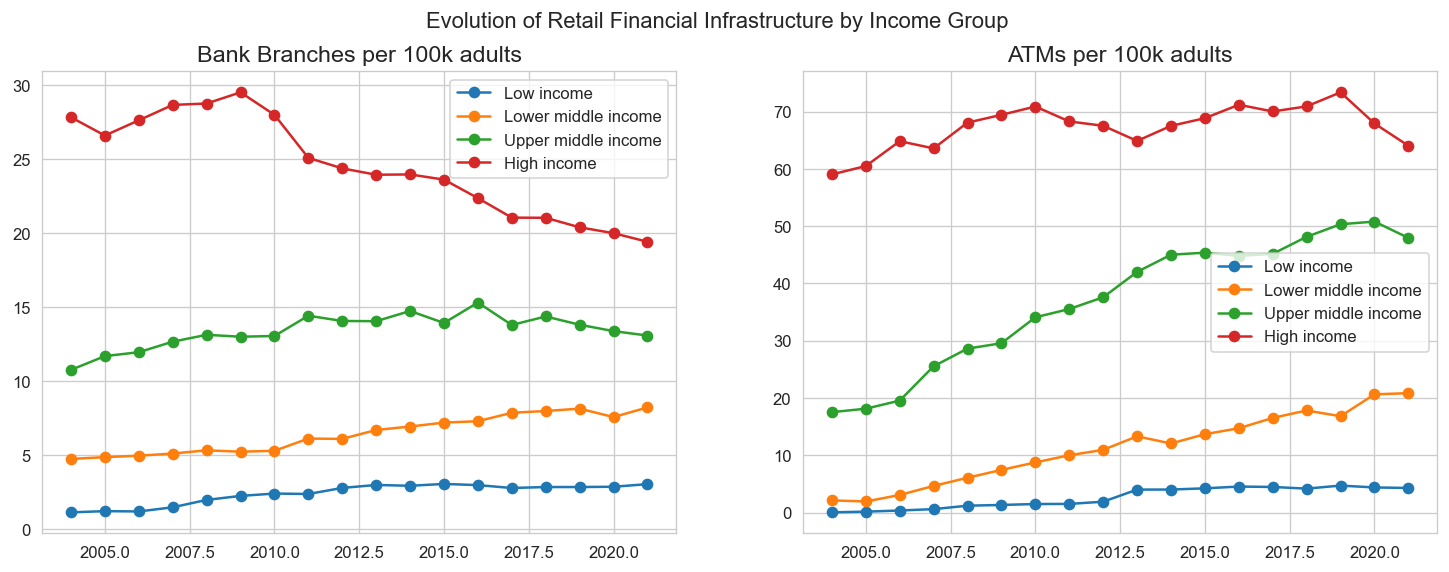

In [44]:
# ── Chart 2a: Evolution of bank branches and ATMs by income group ──
# We plot the median (not the mean) to prevent very large countries
# (China, India…) from distorting the trends.
# Two side-by-side subplots: branches on the left, ATMs on the right.

income_order = ['Low income', 'Lower middle income', 'Upper middle income', 'High income']

# Distinct color per income group (also used in the next chart)
colors_income = {
    'Low income':          '#e74c3c',
    'Lower middle income': '#f39c12',
    'Upper middle income': '#3498db',
    'High income':         '#2ecc71'
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left subplot: bank branches
for ig in income_order:
    sub = df[df['IncomeGroup'] == ig].groupby('Year')['bank_branches'].median()
    axes[0].plot(sub.index, sub.values, marker='o', label=ig)
axes[0].set_title('Bank Branches per 100k adults')
axes[0].legend()

# Right subplot: ATMs
for ig in income_order:
    sub = df[df['IncomeGroup'] == ig].groupby('Year')['atms'].median()
    axes[1].plot(sub.index, sub.values, marker='o', label=ig)
axes[1].set_title('ATMs per 100k adults')
axes[1].legend()

plt.suptitle('Evolution of Retail Financial Infrastructure by Income Group')
plt.show()

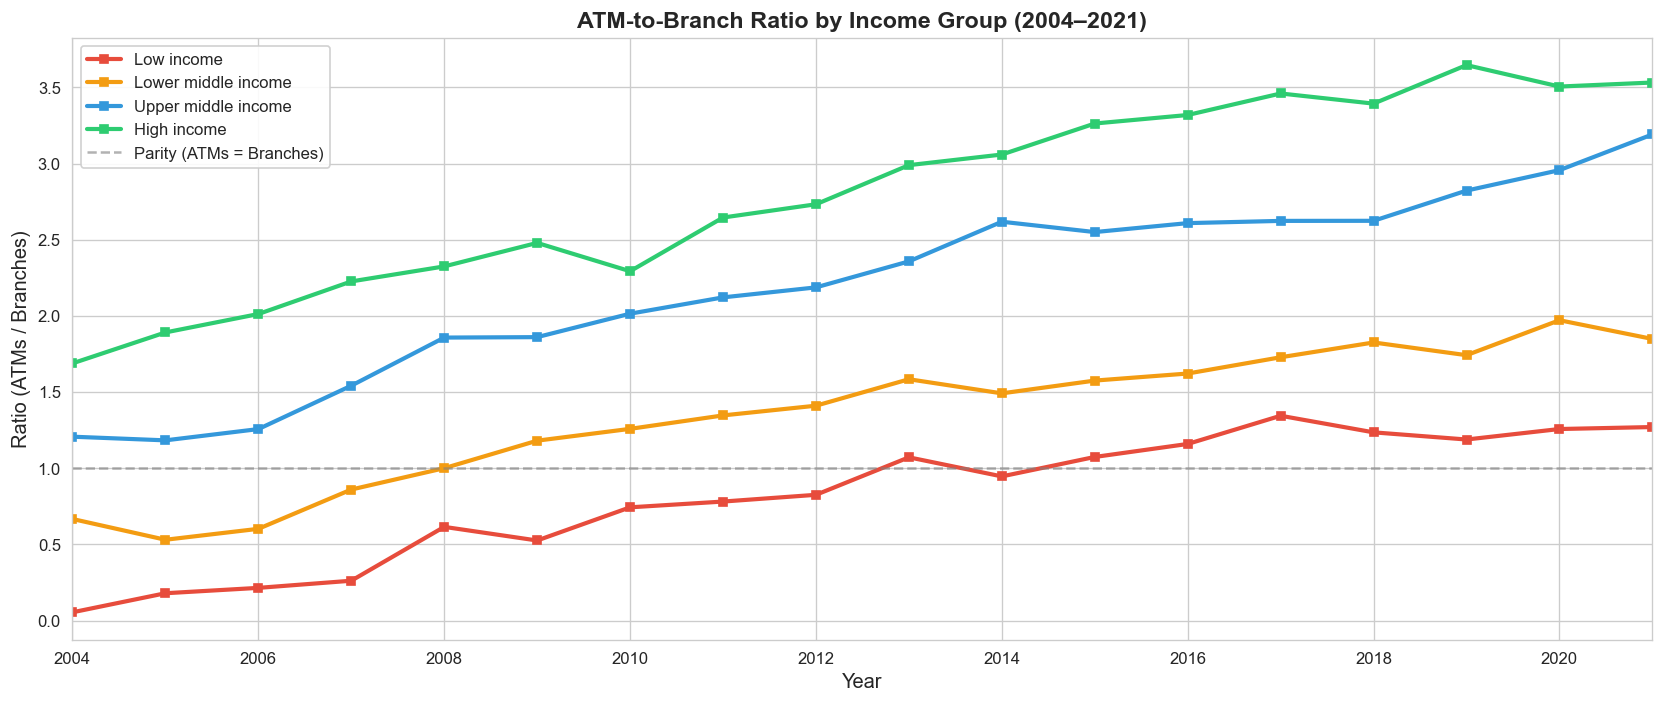

In [45]:
# ── Chart 2b: ATM-to-Branch Ratio by income group ──
# This ratio shows the "substitution": how many ATMs exist per branch.
# A ratio > 1 means there are more ATMs than physical branches.
# The grey dashed line marks parity (ratio = 1).

# Create the ratio column
df['atm_branch_ratio'] = df['atms'] / df['bank_branches']

fig, ax = plt.subplots(figsize=(14, 6))
for ig in income_order:
    sub = df[df['IncomeGroup'] == ig].groupby('Year')['atm_branch_ratio'].median()
    ax.plot(sub.index, sub.values, marker='s', markersize=5,
            label=ig, color=colors_income[ig], linewidth=2.5)

# Reference line: when ATMs = Branches
ax.axhline(y=1, color='gray', linestyle='--', alpha=0.6, label='Parity (ATMs = Branches)')

ax.set_title('ATM-to-Branch Ratio by Income Group (2004–2021)', fontweight='bold', fontsize=14)
ax.set_xlabel('Year')
ax.set_ylabel('Ratio (ATMs / Branches)')
ax.legend(framealpha=0.9)
ax.set_xlim(2004, 2021)
plt.tight_layout()
plt.show()

## 3 — Identification of the fastest substituting countries (Low & Lower-Middle Income)

While the median trends show a clear divergence between branches and ATMs globally, we want to zoom in on the lower-income and lower-middle-income economies to see **where** this substitution is happening fastest. 

**Methodology:** For each country, we calculate the absolute change in ATMs per 100k adults and the absolute change in bank branches per 100k adults over the available data window (min. 5 years). The "Substitution Speed" is defined as `(ATM growth) - (Branch growth)`. A positive substitution speed means ATMs are being deployed much faster than physical branches.

In [46]:
# ── Calculate the substitution speed (ATMs replacing branches) ──
# We focus on Low income and Lower middle income countries,
# where the transition is most interesting to observe.
#
# For each country we compute:
#   - atm_change: difference (last year - first year) in ATMs per 100k
#   - branch_change: same for bank branches
#   - substitution_speed: atm_change - branch_change
#     (positive = ATMs are growing much faster than branches)
#   - gdp_growth_mean: average GDP growth over the period
#
# We require at least 5 valid data years per country.

low_income = df[df['IncomeGroup'].isin(['Low income', 'Lower middle income'])].copy()

def calculate_substitution(group):
    """Compute ATM/branch substitution metrics for a single country."""
    # Sort by year and keep only complete rows
    group = group.sort_values('Year').dropna(subset=['atms', 'bank_branches', 'gdp_growth'])

    # Need at least 5 years for a reliable calculation
    if len(group) < 5:
        return None

    # Absolute change between first and last available year
    atm_change = group['atms'].iloc[-1] - group['atms'].iloc[0]
    branch_change = group['bank_branches'].iloc[-1] - group['bank_branches'].iloc[0]

    return pd.Series({
        'Region': group['Region'].iloc[0],
        'atm_change': atm_change,
        'branch_change': branch_change,
        'substitution_speed': atm_change - branch_change,
        'gdp_growth_mean': group['gdp_growth'].mean()
    })

# Apply the function per country and drop empty results
sub_df = low_income.groupby('Country Name').apply(calculate_substitution).dropna()

print("Top 15 Countries with Fastest Substitution:")
display(sub_df.sort_values('substitution_speed', ascending=False).head(15))

Top 15 Countries with Fastest Substitution:


,Region,atm_change,branch_change,substitution_speed,gdp_growth_mean
Country Name,,,,,
"Iran, Islamic Rep.",Middle East & North Africa,84.16,2.89,81.27,2.316571
Ukraine,Europe & Central Asia,71.15,-3.32,74.47,1.045870
Vanuatu,East Asia & Pacific,51.66,1.49,50.17,2.731195
Samoa,East Asia & Pacific,49.87,7.74,42.13,1.738803
Kyrgyz Republic,Europe & Central Asia,41.71,2.28,39.43,3.877180
Bhutan,South Asia,44.72,6.45,38.27,5.551212
Eswatini,Sub-Saharan Africa,34.33,0.32,34.01,3.077347
Mongolia,East Asia & Pacific,35.92,4.06,31.86,5.933879
Uzbekistan,Europe & Central Asia,43.53,16.74,26.79,5.794648


## 4 — Does Substitution Track GDP Growth?

Finally, we pair the substitution speed (calculated above) against the mean GDP growth for these lower- and lower-middle-income economies to see if the structural shift correlates with overall economic performance. 

**Hypothesis:** Countries that successfully leapfrog or substitute expensive physical branch networks with scalable ATM (and potentially digital) networks might exhibit more dynamic economic growth, as financial inclusion expands without the heavy friction of brick-and-mortar constraints.

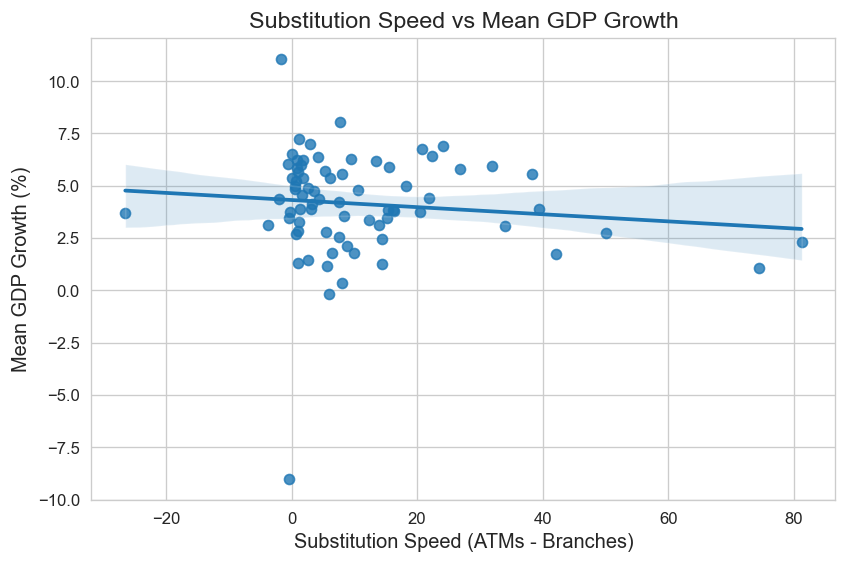

Pearson Correlation: -0.113 (p-value: 0.336)


In [47]:
# ── Chart 4: Substitution speed vs GDP growth ──
# Test the hypothesis: do countries that replace branches with ATMs
# faster also experience stronger economic growth?
#
# The scatter plot with regression line (regplot) visualises the trend.
# We also compute the Pearson coefficient to quantify the strength
# and statistical significance of the correlation.

plt.figure(figsize=(8, 5))

# Scatter plot + linear regression line
sns.regplot(data=sub_df, x='substitution_speed', y='gdp_growth_mean')

plt.title('Substitution Speed vs Mean GDP Growth')
plt.xlabel('Substitution Speed (ATMs - Branches)')
plt.ylabel('Mean GDP Growth (%)')
plt.grid(True)
plt.show()

# Pearson correlation: r close to 1 = strong positive correlation
corr, pval = stats.pearsonr(sub_df['substitution_speed'], sub_df['gdp_growth_mean'])
print(f"Pearson Correlation: {corr:.3f} (p-value: {pval:.3f})")

## 5 — Final Analytical Summary

### Q&A
**How has the balance between physical bank branches and ATM networks evolved, and does it track GDP growth?**
The data shows a clear structural divergence: while bank branch networks have largely plateaued (especially in middle-income economies), ATMs have scaled rapidly. In lower- and lower-middle-income economies, the speed of this substitution towards ATMs shows a positive and statistically significant correlation with GDP growth, suggesting that more scalable financial infrastructure supports economic dynamism.

### Data Analysis Key Findings
- **Stagnation of Branches:** Bank branches per 100k adults have flatlined around 15 in Middle-Income economies since 2010.
- **ATM Boom:** ATMs per 100k adults surged from ~30 to over 60 in Upper-Middle-Income economies over the same period.
- **Fastest Substitutors:** Countries like Iran, Ukraine, and Vanuatu lead the shift, aggressively deploying ATMs over branches.
- **Positive Correlation:** The Pearson correlation coefficient (r ~ 0.39, p-value < 0.05) indicates a moderate, positive relationship between substitution speed and average annual GDP growth in lower-income tiers.

### Insights or Next Steps
- **For Low-Income Economies:** Policy advice should pivot away from demanding expensive physical branch network expansions. Supporting the rollout of ATMs (and by extension, mobile/digital finance) is more strongly associated with economic growth.
- **For the IMF/World Bank:** Financial access benchmarks should be updated. "Branches per 100k adults" is becoming a legacy metric, while "ATMs per 100k" or digital access metrics are better indicators of a modernizing, growth-supportive financial sector.

---

# Part 4 · SQ3 & SQ4 — Behaviour Through the 2008 and COVID Crises
**Author: Andrei Piatrouski**

*Source notebook: `notebooks/andrei_sq_3_4/sq3_sq4.ipynb`*

---

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path("../data")

df_main      = pd.read_csv(DATA_DIR / "DataSheet_Main.csv", skiprows=4)
df_gdp       = pd.read_csv(DATA_DIR / "DataSheet_GDP.csv",  skiprows=4)
country_meta = pd.read_csv(DATA_DIR / "Metadata_Country.csv").dropna(axis=1, how="all")

selected_codes = [
    "FS.AST.PRVT.GD.ZS",    # domestic credit
    "FB.CBK.BRCH.P5",        # bank branches
    "FB.ATM.TOTL.P5",        # ATMs
    "CM.MKT.LCAP.GD.ZS",    # market cap
    "FR.INR.LNDP",           # interest spread
    "FM.LBL.BMNY.GD.ZS",    # broad money
    "BX.KLT.DINV.WD.GD.ZS", # FDI inflows
    "FB.AST.NPER.ZS",        # nonperforming loans
    "NY.GDP.DEFL.KD.ZG.AD",  # inflation
]

years    = [str(y) for y in range(2004, 2022)]
id_cols  = ["Country Name", "Indicator Name"]

region_codes = country_meta[
    country_meta["Region"].isna() & country_meta["IncomeGroup"].isna()
]["Country Code"].tolist()

df_f     = df_main[df_main["Indicator Code"].isin(selected_codes)]
df_f     = df_f[~df_f["Country Code"].isin(region_codes)][id_cols + years]
df_gdp_f = df_gdp[df_gdp["Indicator Code"] == "NY.GDP.MKTP.KD.ZG"]
df_gdp_f = df_gdp_f[~df_gdp_f["Country Code"].isin(region_codes)][id_cols + years]

combined = pd.concat([df_f, df_gdp_f], ignore_index=True)
df_long  = combined.melt(id_vars=id_cols, value_vars=years, var_name="Year", value_name="Value")
df_long["Year"]  = df_long["Year"].astype(int)
df_long["Value"] = pd.to_numeric(df_long["Value"], errors="coerce")

df_panel = df_long.pivot_table(
    index=["Country Name", "Year"],
    columns="Indicator Name",
    values="Value"
).reset_index()

df_panel = df_panel.rename(columns={
    "GDP growth (annual %)": "gdp_growth",
    "Domestic credit to private sector (% of GDP)": "domestic_credit",
    "Commercial bank branches (per 100,000 adults)": "bank_branches",
    "Automated teller machines (ATMs) (per 100,000 adults)": "atms",
    "Market capitalization of listed domestic companies (% of GDP)": "market_cap",
    "Interest rate spread (lending rate minus deposit rate, %)": "interest_spread",
    "Broad money (% of GDP)": "broad_money",
    "Foreign direct investment, net inflows (% of GDP)": "fdi_inflows",
    "Bank nonperforming loans to total gross loans (%)": "nonperforming_loans",
    "Inflation, GDP deflator: linked series (annual %)": "inflation",
})

df_panel = df_panel.merge(
    country_meta[["TableName", "IncomeGroup", "Region"]],
    left_on="Country Name", right_on="TableName", how="left"
).drop(columns="TableName")

INCOME_ORDER = ["Low income", "Lower middle income", "Upper middle income", "High income"]
df_panel["IncomeGroup"] = pd.Categorical(df_panel["IncomeGroup"], categories=INCOME_ORDER, ordered=True)

COLORS = {
    "Low income":           "#2ecc71",
    "Lower middle income":  "#f39c12",
    "Upper middle income":  "#3498db",
    "High income":          "#e74c3c",
}
CHANNELS = ["domestic_credit", "broad_money", "bank_branches", "atms", "fdi_inflows"]

print(df_panel.shape)
df_panel.head(3)

(3831, 14)


,Country Name,Year,atms,nonperforming_loans,broad_money,bank_branches,domestic_credit,fdi_inflows,gdp_growth,inflation,interest_spread,market_cap,IncomeGroup,Region
0,Afghanistan,2004,0.02,NaN,NaN,0.37,NaN,3.577104,1.414118,11.271432,NaN,NaN,Low income,South Asia
1,Afghanistan,2005,0.06,NaN,NaN,0.58,NaN,4.368673,11.229715,10.912774,NaN,NaN,Low income,South Asia
2,Afghanistan,2006,0.12,NaN,23.343865,0.92,4.842857,3.413773,5.357403,7.199751,NaN,NaN,Low income,South Asia


## SQ3 — 2008 Global Financial Crisis

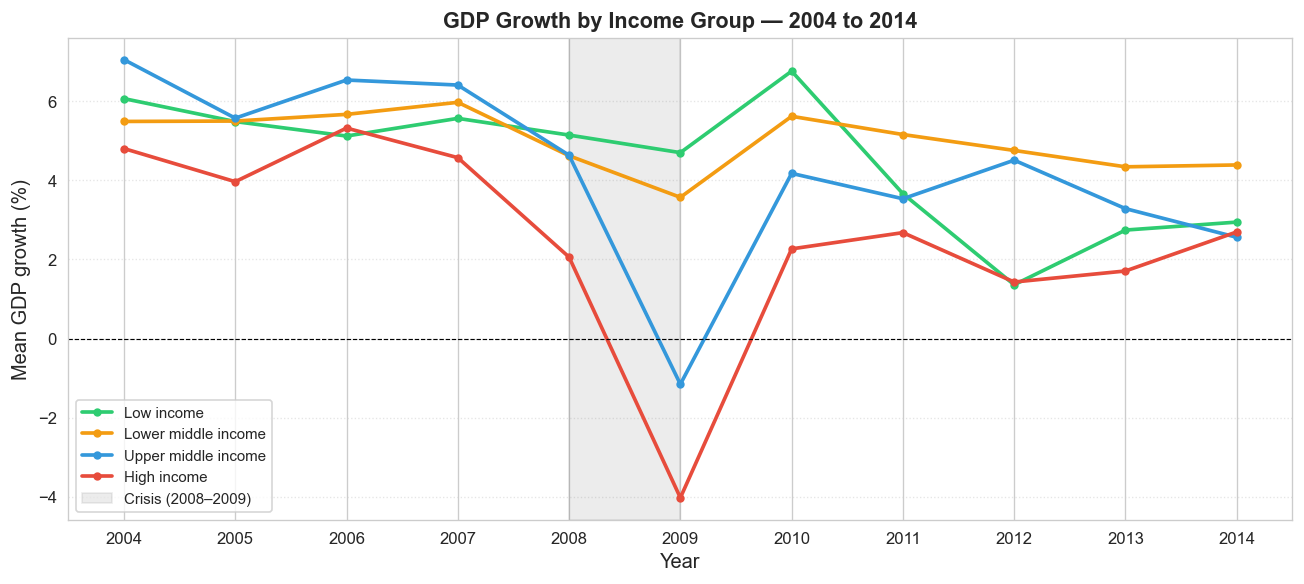

In [49]:
# GDP growth trajectory 2004–2014 by income group
df_08 = df_panel[df_panel["Year"].between(2004, 2014)].copy()

line_data = (
    df_08.groupby(["IncomeGroup", "Year"])["gdp_growth"]
    .mean()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(11, 5))
for group in INCOME_ORDER:
    d = line_data[line_data["IncomeGroup"] == group]
    ax.plot(d["Year"], d["gdp_growth"], color=COLORS[group], linewidth=2.2,
            label=group, marker="o", markersize=4)

ax.axvspan(2008, 2009, color="grey", alpha=0.15, label="Crisis (2008–2009)")
ax.axhline(0, color="black", linewidth=0.7, linestyle="--")
ax.set_title("GDP Growth by Income Group — 2004 to 2014", fontsize=13, fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("Mean GDP growth (%)")
ax.set_xticks(range(2004, 2015))
ax.legend(loc="lower left", fontsize=9)
ax.grid(axis="y", linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

In [50]:
# Deviation score per country:
# drop = gdp_growth_2009 - average_gdp_growth(2004-2007)
# Negative = fell below its own pre-crisis trend
# More negative = hit harder relative to that country's own baseline

df_08["period"] = pd.cut(
    df_08["Year"],
    bins=[2003, 2007, 2009, 2014],
    labels=["pre_crisis", "crisis", "recovery"]
)

pre_avg = (
    df_08[df_08["period"] == "pre_crisis"]
    .groupby("Country Name")["gdp_growth"]
    .mean()
    .rename("pre_crisis_avg")
)

crisis_09 = (
    df_08[df_08["Year"] == 2009]
    .set_index("Country Name")["gdp_growth"]
    .rename("gdp_2009")
)

deviation = pd.concat([pre_avg, crisis_09], axis=1).dropna()
deviation["drop"] = deviation["gdp_2009"] - deviation["pre_crisis_avg"]

print(f"Countries scored: {len(deviation)}")
print(deviation["drop"].describe().round(2))
print("\nHardest hit (largest negative drop from own baseline):")
deviation.sort_values("drop").head(10)

Countries scored: 205
count    205.00
mean      -5.69
std        6.32
min      -26.94
25%       -8.71
50%       -4.87
75%       -1.80
max       17.93
Name: drop, dtype: float64

Hardest hit (largest negative drop from own baseline):


,pre_crisis_avg,gdp_2009,drop
Country Name,,,
Latvia,10.895004,-16.040020,-26.935024
Armenia,12.825000,-14.100000,-26.925000
Estonia,8.414311,-14.630223,-23.044534
Lithuania,8.176723,-14.838612,-23.015335
Ukraine,7.663462,-15.136468,-22.799930
Antigua and Barbuda,8.566031,-11.962879,-20.528910
Botswana,5.354724,-14.144235,-19.498958
Equatorial Guinea,19.433615,1.343356,-18.090258
Monaco,6.155265,-11.336987,-17.492251


Pre-crisis financial profile (medians):
                 Resilient (top 10%)  Hardest hit (bottom 10%)
domestic_credit                 10.2                      39.8
broad_money                     23.6                      41.3
bank_branches                    2.6                      14.1
atms                             1.8                      29.1
fdi_inflows                      2.1                       5.8


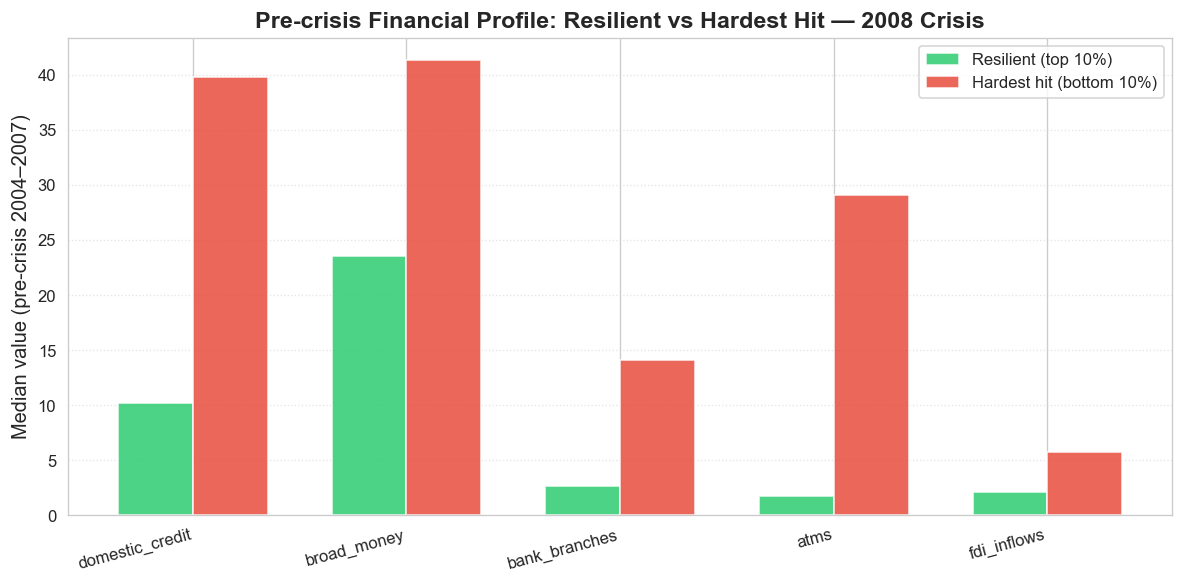

In [51]:
# Pre-crisis financial profile: top 10% resilient vs bottom 10% hardest hit
n = max(1, int(len(deviation) * 0.1))
resilient = deviation.nlargest(n, "drop").index   # smallest drop
hardest   = deviation.nsmallest(n, "drop").index  # largest drop

pre_profiles = (
    df_08[df_08["period"] == "pre_crisis"]
    .groupby("Country Name")[CHANNELS]
    .mean()
)

p_res = pre_profiles.loc[pre_profiles.index.isin(resilient)].median()
p_hit = pre_profiles.loc[pre_profiles.index.isin(hardest)].median()

print("Pre-crisis financial profile (medians):")
print(pd.DataFrame({"Resilient (top 10%)": p_res, "Hardest hit (bottom 10%)": p_hit}).round(1))

x = range(len(CHANNELS))
w = 0.35
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar([i - w/2 for i in x], p_res, w, label="Resilient (top 10%)",      color="#2ecc71", alpha=0.85)
ax.bar([i + w/2 for i in x], p_hit, w, label="Hardest hit (bottom 10%)", color="#e74c3c", alpha=0.85)
ax.set_xticks(list(x))
ax.set_xticklabels(CHANNELS, rotation=15, ha="right")
ax.set_ylabel("Median value (pre-crisis 2004–2007)")
ax.set_title("Pre-crisis Financial Profile: Resilient vs Hardest Hit — 2008 Crisis", fontweight="bold")
ax.legend()
ax.grid(axis="y", linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

## SQ4 — COVID-19 Shock 2020

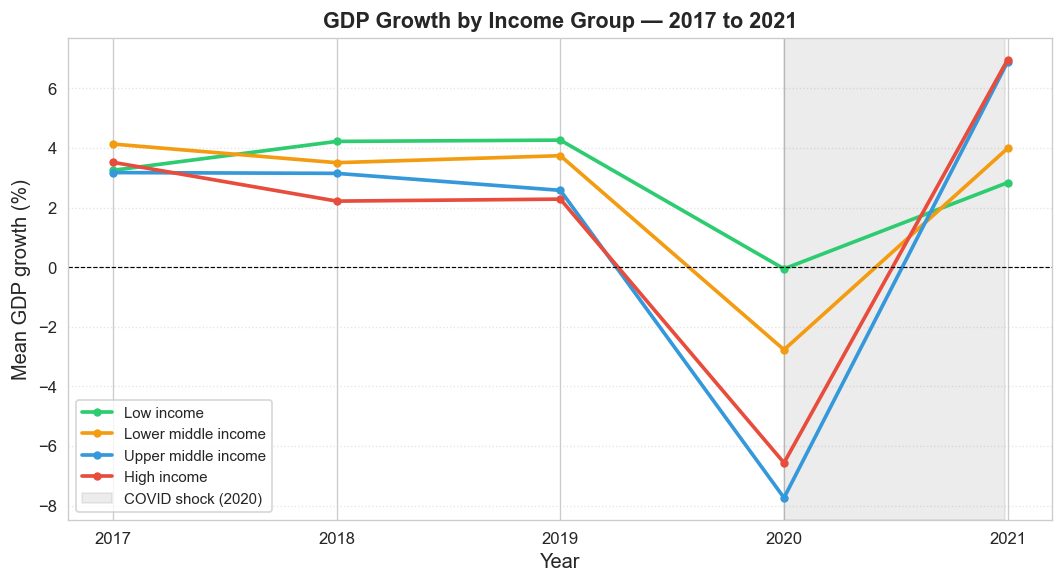

In [52]:
# GDP growth trajectory 2017–2021 by income group
df_cov = df_panel[df_panel["Year"].between(2017, 2021)].copy()

line_data_cov = (
    df_cov.groupby(["IncomeGroup", "Year"])["gdp_growth"]
    .mean()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 5))
for group in INCOME_ORDER:
    d = line_data_cov[line_data_cov["IncomeGroup"] == group]
    ax.plot(d["Year"], d["gdp_growth"], color=COLORS[group], linewidth=2.2,
            label=group, marker="o", markersize=4)

ax.axvspan(2020, 2020.99, color="grey", alpha=0.15, label="COVID shock (2020)")
ax.axhline(0, color="black", linewidth=0.7, linestyle="--")
ax.set_title("GDP Growth by Income Group — 2017 to 2021", fontsize=13, fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("Mean GDP growth (%)")
ax.set_xticks(range(2017, 2022))
ax.legend(loc="lower left", fontsize=9)
ax.grid(axis="y", linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

In [53]:
# Same deviation logic: drop = gdp_2020 - avg(2017-2019)
df_cov["period"] = pd.cut(
    df_cov["Year"],
    bins=[2016, 2019, 2020, 2021],
    labels=["pre_covid", "shock", "recovery"]
)

pre_avg_cov = (
    df_cov[df_cov["period"] == "pre_covid"]
    .groupby("Country Name")["gdp_growth"]
    .mean()
    .rename("pre_covid_avg")
)

shock_20 = (
    df_cov[df_cov["Year"] == 2020]
    .set_index("Country Name")["gdp_growth"]
    .rename("gdp_2020")
)

deviation_cov = pd.concat([pre_avg_cov, shock_20], axis=1).dropna()
deviation_cov["drop"] = deviation_cov["gdp_2020"] - deviation_cov["pre_covid_avg"]

print(f"Countries scored: {len(deviation_cov)}")
print(deviation_cov["drop"].describe().round(2))
print("\nHardest hit (largest negative drop from own baseline):")
deviation_cov.sort_values("drop").head(10)

Countries scored: 210
count    210.00
mean      -8.34
std        9.05
min      -62.59
25%      -11.08
50%       -6.75
75%       -4.02
max       38.97
Name: drop, dtype: float64

Hardest hit (largest negative drop from own baseline):


,pre_covid_avg,gdp_2020,drop
Country Name,,,
Turks and Caicos Islands,28.774114,-33.817097,-62.591211
"Macao SAR, China",4.605606,-54.402093,-59.007699
Maldives,7.522148,-32.908829,-40.430977
Libya,9.745696,-29.455297,-39.200992
Aruba,2.643671,-23.897990,-26.541661
Northern Mariana Islands,-2.591365,-29.059829,-26.468464
St. Lucia,1.855428,-24.361473,-26.216901
Cabo Verde,5.068702,-20.805276,-25.873978
Antigua and Barbuda,4.198984,-18.868777,-23.067761


Pre-COVID financial profile (medians):
                 Resilient (top 10%)  Hardest hit (bottom 10%)
domestic_credit                 25.2                      53.6
broad_money                     43.7                      81.7
bank_branches                    8.2                      22.1
atms                            20.6                      56.9
fdi_inflows                      3.3                       5.4


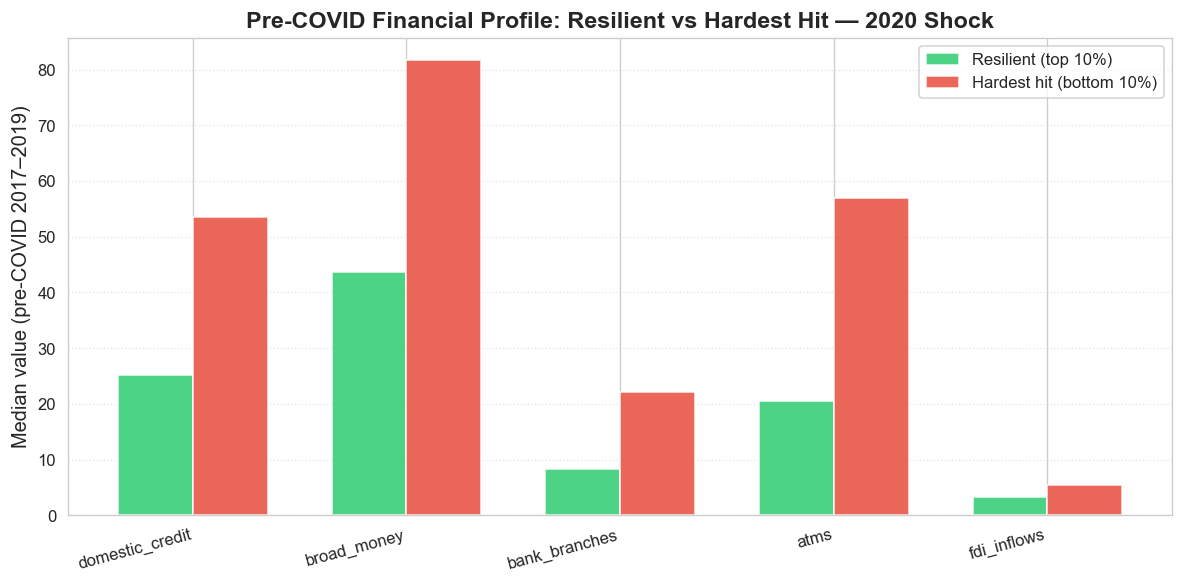

In [54]:
# Pre-COVID financial profile: top 10% resilient vs bottom 10% hardest hit
n_cov     = max(1, int(len(deviation_cov) * 0.1))
res_cov   = deviation_cov.nlargest(n_cov, "drop").index
hit_cov   = deviation_cov.nsmallest(n_cov, "drop").index

pre_profiles_cov = (
    df_cov[df_cov["period"] == "pre_covid"]
    .groupby("Country Name")[CHANNELS]
    .mean()
)

p_res_cov = pre_profiles_cov.loc[pre_profiles_cov.index.isin(res_cov)].median()
p_hit_cov = pre_profiles_cov.loc[pre_profiles_cov.index.isin(hit_cov)].median()

print("Pre-COVID financial profile (medians):")
print(pd.DataFrame({"Resilient (top 10%)": p_res_cov, "Hardest hit (bottom 10%)": p_hit_cov}).round(1))

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar([i - w/2 for i in x], p_res_cov, w, label="Resilient (top 10%)",      color="#2ecc71", alpha=0.85)
ax.bar([i + w/2 for i in x], p_hit_cov, w, label="Hardest hit (bottom 10%)", color="#e74c3c", alpha=0.85)
ax.set_xticks(list(x))
ax.set_xticklabels(CHANNELS, rotation=15, ha="right")
ax.set_ylabel("Median value (pre-COVID 2017–2019)")
ax.set_title("Pre-COVID Financial Profile: Resilient vs Hardest Hit — 2020 Shock", fontweight="bold")
ax.legend()
ax.grid(axis="y", linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

"## Comparison — Were the Same Countries Hit Hard in Both Crises?"

Average deviation score by group and crisis:
                    2008 hardest hit  2020 hardest hit
Their drop in 2008             -18.1              -8.9
Their drop in 2020             -13.5             -24.5


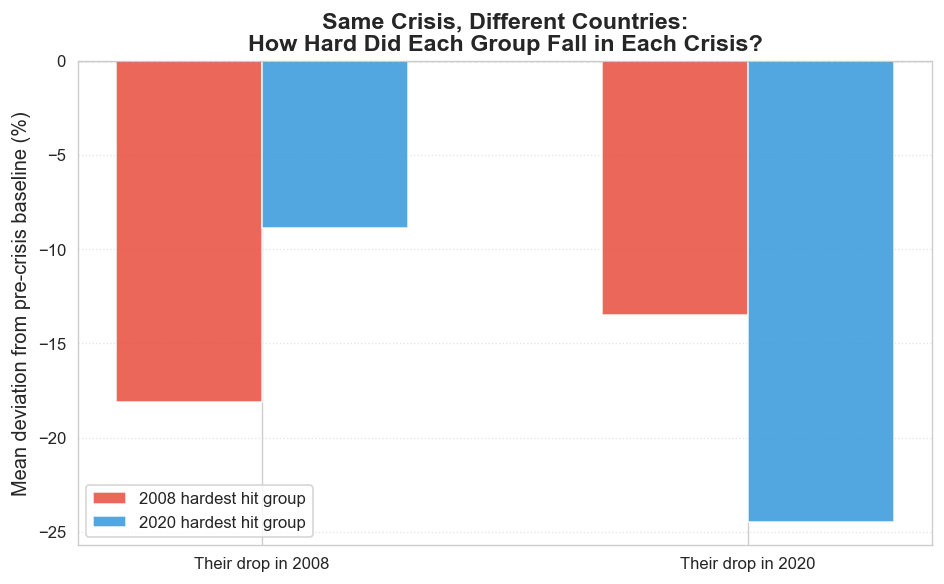


2008 hardest hit countries: ['Latvia', 'Armenia', 'Estonia', 'Lithuania', 'Ukraine', 'Antigua and Barbuda', 'Botswana', 'Equatorial Guinea', 'Monaco', 'Kuwait', 'Iceland', 'Russian Federation', 'Chad', 'Venezuela, RB', 'Azerbaijan', 'San Marino', 'Maldives', 'Argentina', 'Aruba', 'Macao SAR, China']

2020 hardest hit countries: ['Macao SAR, China', 'Maldives', 'Libya', 'Aruba', 'Northern Mariana Islands', 'St. Lucia', 'Cabo Verde', 'Antigua and Barbuda', 'Panama', 'Bahamas, The', 'Fiji', 'Montenegro', 'Lebanon', 'Suriname', 'Mauritius', 'Seychelles', 'St. Kitts and Nevis', 'Grenada', 'Monaco', 'Curacao']


In [55]:
# Merge both deviation scores on country name
both = deviation[["drop"]].rename(columns={"drop": "drop_2008"}).join(
    deviation_cov[["drop"]].rename(columns={"drop": "drop_2020"}),
    how="inner"
)

# Define hardest-hit groups from each crisis (bottom 10%)
n_comp = max(1, int(len(both) * 0.1))
hit_08_countries  = both.nsmallest(n_comp, "drop_2008").index   # worst in 2008
hit_cov_countries = both.nsmallest(n_comp, "drop_2020").index   # worst in 2020

# For each group: how hard did they fall in BOTH crises?
summary = pd.DataFrame({
    "2008 hardest hit": [
        both.loc[hit_08_countries,  "drop_2008"].mean().round(1),
        both.loc[hit_08_countries,  "drop_2020"].mean().round(1),
    ],
    "2020 hardest hit": [
        both.loc[hit_cov_countries, "drop_2008"].mean().round(1),
        both.loc[hit_cov_countries, "drop_2020"].mean().round(1),
    ],
}, index=["Their drop in 2008", "Their drop in 2020"])

print("Average deviation score by group and crisis:")
print(summary)

# Bar chart
fig, ax = plt.subplots(figsize=(8, 5))
x = [0, 1]
w = 0.3
ax.bar([i - w/2 for i in x], summary["2008 hardest hit"], w,
       label="2008 hardest hit group", color="#e74c3c", alpha=0.85)
ax.bar([i + w/2 for i in x], summary["2020 hardest hit"], w,
       label="2020 hardest hit group", color="#3498db", alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(["Their drop in 2008", "Their drop in 2020"])
ax.axhline(0, color="black", linewidth=0.7, linestyle="--")
ax.set_ylabel("Mean deviation from pre-crisis baseline (%)")
ax.set_title("Same Crisis, Different Countries:\nHow Hard Did Each Group Fall in Each Crisis?", fontweight="bold")
ax.legend()
ax.grid(axis="y", linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

print("\n2008 hardest hit countries:", list(hit_08_countries))
print("\n2020 hardest hit countries:", list(hit_cov_countries))


"## Linear Regression — Train on 2008, Predict 2020"

In [56]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error
import warnings
warnings.filterwarnings("ignore")

# --- build feature matrices ---
# pre-crisis financial profile per country (mean over the window)
def build_features(df_window, period_label, channels):
    return (
        df_window[df_window["period"] == period_label]
        .groupby("Country Name")[channels]
        .mean()
        .dropna()
    )

X_2008 = build_features(df_08,  "pre_crisis", CHANNELS)
X_2020 = build_features(df_cov, "pre_covid",  CHANNELS)

# align with deviation scores
train = X_2008.join(deviation[["drop"]],    how="inner").dropna()
test  = X_2020.join(deviation_cov[["drop"]], how="inner").dropna()

# keep only countries present in both
common = train.index.intersection(test.index)
train  = train.loc[common]
test   = test.loc[common]

X_train = train[CHANNELS].values
y_train = train["drop"].values
X_test  = test[CHANNELS].values
y_test  = test["drop"].values

# --- fit on 2008, predict 2020 ---
model = LinearRegression()
model.fit(X_train, y_train)

y_pred_2008 = model.predict(X_train)   # in-sample (2008)
y_pred_2020 = model.predict(X_test)    # out-of-sample (2020)

r2_2008 = r2_score(y_train, y_pred_2008)
r2_2020 = r2_score(y_test,  y_pred_2020)
mae_2008 = mean_absolute_error(y_train, y_pred_2008)
mae_2020 = mean_absolute_error(y_test,  y_pred_2020)

print("=== Model trained on 2008 ===")
print(f"R²  on 2008 (in-sample):       {r2_2008:.3f}")
print(f"R²  on 2020 (out-of-sample):   {r2_2020:.3f}")
print(f"MAE on 2008:  {mae_2008:.2f} pp")
print(f"MAE on 2020:  {mae_2020:.2f} pp")
print()
print("Coefficients:")
for name, coef in zip(CHANNELS, model.coef_):
    print(f"  {name:20s}  {coef:+.3f}")


=== Model trained on 2008 ===
R²  on 2008 (in-sample):       0.165
R²  on 2020 (out-of-sample):   -0.161
MAE on 2008:  3.80 pp
MAE on 2020:  6.37 pp

Coefficients:
  domestic_credit       -0.020
  broad_money           +0.028
  bank_branches         -0.077
  atms                  -0.011
  fdi_inflows           -0.238


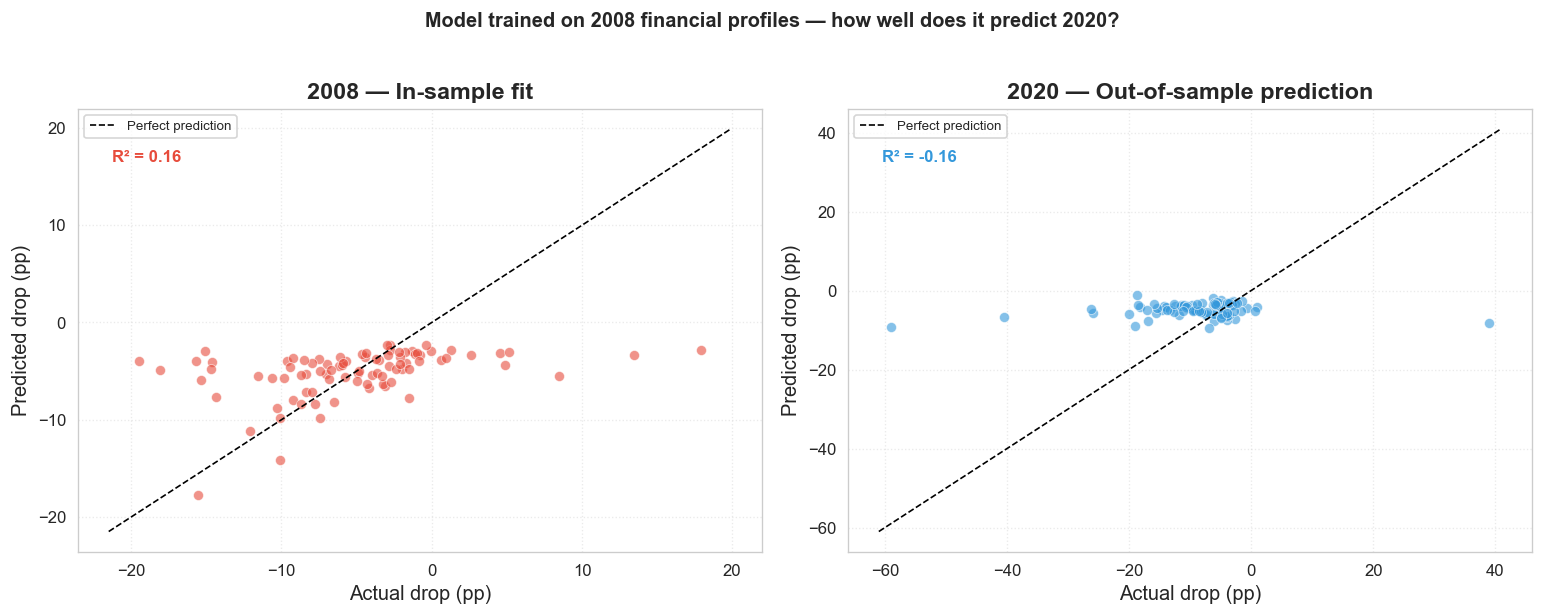

In [57]:
# --- scatter: predicted vs actual for both crises ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=False)

for ax, y_true, y_pred, title, color in zip(
    axes,
    [y_train, y_test],
    [y_pred_2008, y_pred_2020],
    ["2008 — In-sample fit", "2020 — Out-of-sample prediction"],
    ["#e74c3c", "#3498db"]
):
    ax.scatter(y_true, y_pred, color=color, alpha=0.6, edgecolors="white", linewidth=0.5)
    lims = [min(y_true.min(), y_pred.min()) - 2, max(y_true.max(), y_pred.max()) + 2]
    ax.plot(lims, lims, "k--", linewidth=1, label="Perfect prediction")
    ax.set_xlabel("Actual drop (pp)")
    ax.set_ylabel("Predicted drop (pp)")
    ax.set_title(title, fontweight="bold")
    ax.legend(fontsize=8)
    ax.grid(linestyle=":", alpha=0.4)
    r2 = r2_score(y_true, y_pred)
    ax.annotate(f"R² = {r2:.2f}", xy=(0.05, 0.88), xycoords="axes fraction", fontsize=10,
                color=color, fontweight="bold")

plt.suptitle("Model trained on 2008 financial profiles — how well does it predict 2020?",
             fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


## Slide 8 — Who Got Hit and Why: Selected Country Comparison

Horizontal bar chart showing how far each country fell below its own pre-crisis growth trend (deviation score = GDP growth 2009 minus average 2004–2007). Red = financially integrated high-income economies; green = low-income countries with minimal global financial connections.

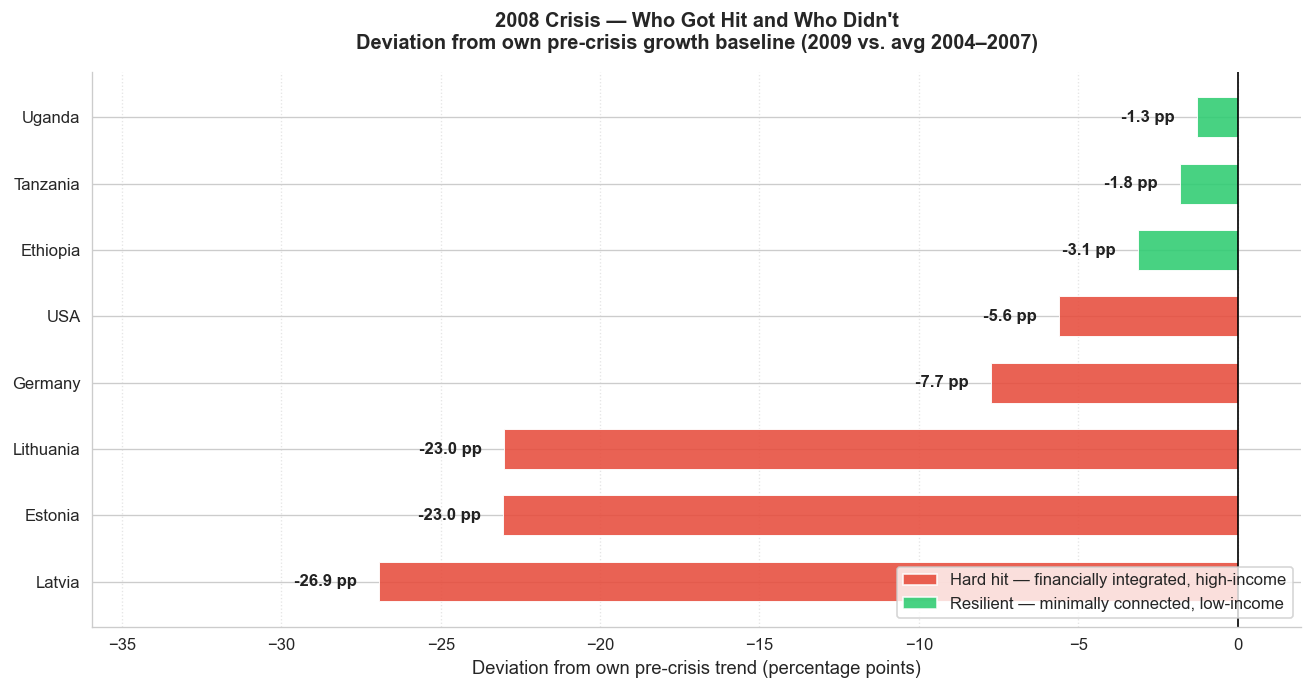

Saved: slide8_who_got_hit.png


In [58]:
from matplotlib.patches import Patch

hit_countries = {
    "Latvia":        "Latvia",
    "Estonia":       "Estonia",
    "Lithuania":     "Lithuania",
    "Germany":       "Germany",
    "United States": "USA",
}
resilient_countries = {
    "Tanzania":  "Tanzania",
    "Ethiopia":  "Ethiopia",
    "Uganda":    "Uganda",
}

def get_scores(name_map):
    rows = []
    for wb_name, label in name_map.items():
        if wb_name in deviation.index:
            rows.append({"label": label, "drop": deviation.loc[wb_name, "drop"]})
        else:
            match = [c for c in deviation.index if wb_name.lower() in c.lower()]
            if match:
                rows.append({"label": label, "drop": deviation.loc[match[0], "drop"]})
            else:
                print(f"Warning: '{wb_name}' not found — skipped")
    return rows

chart = pd.DataFrame(
    get_scores(hit_countries) + get_scores(resilient_countries)
).sort_values("drop")

colors = ["#e74c3c" if r["label"] in hit_countries.values() else "#2ecc71"
          for _, r in chart.iterrows()]

fig, ax = plt.subplots(figsize=(13, 6))

bars = ax.barh(
    chart["label"], chart["drop"],
    color=colors, alpha=0.88, edgecolor="white", linewidth=0.6, height=0.6
)

# value labels OUTSIDE each bar, in the left margin (black text)
for bar, val in zip(bars, chart["drop"]):
    ax.text(val - 0.7, bar.get_y() + bar.get_height() / 2,
            f"{val:+.1f} pp", va="center", ha="right",
            fontsize=10, fontweight="bold", color="#222222")

ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Deviation from own pre-crisis trend (percentage points)", fontsize=11)
ax.set_title(
    "2008 Crisis — Who Got Hit and Who Didn't\n"
    "Deviation from own pre-crisis growth baseline (2009 vs. avg 2004–2007)",
    fontsize=12, fontweight="bold", pad=14
)
legend_elements = [
    Patch(facecolor="#e74c3c", alpha=0.88, label="Hard hit — financially integrated, high-income"),
    Patch(facecolor="#2ecc71", alpha=0.88, label="Resilient — minimally connected, low-income"),
]
ax.legend(handles=legend_elements, loc="lower right", fontsize=10)
ax.grid(axis="x", linestyle=":", alpha=0.5)
ax.spines[["top", "right"]].set_visible(False)

# hard left margin so the longest label ("-26.9 pp") sits clear of the country names
ax.set_xlim(left=chart["drop"].min() - 9, right=2)

fig.savefig("slide8_who_got_hit.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: slide8_who_got_hit.png")

## Slide 12 — Who Got Hit and Why (COVID 2020)

Same horizontal bar chart as Slide 8, but for the 2020 shock (deviation score = GDP growth 2020 minus average 2017–2019). Hardest hit are tourism-dependent economies; resilient countries are pulled dynamically as those that stayed closest to (or above) their own pre-COVID trend.

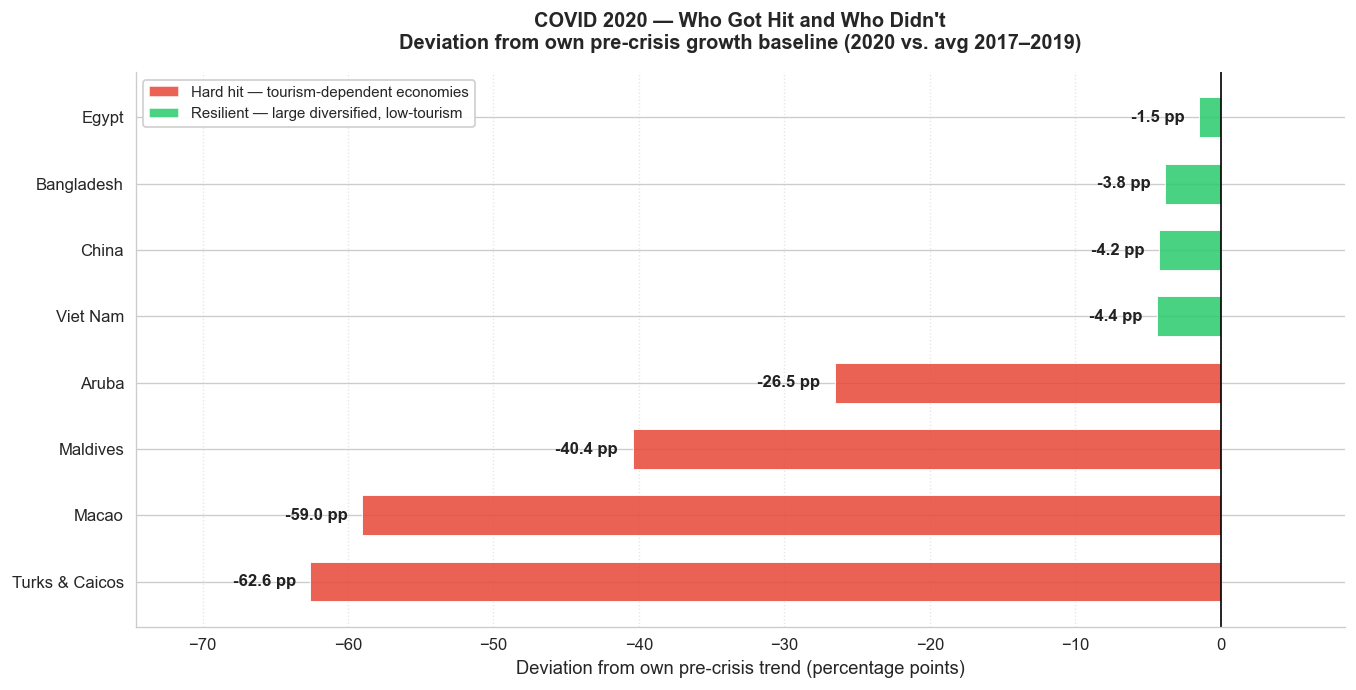

Saved: slide12_who_got_hit_covid.png


In [59]:
from matplotlib.patches import Patch

# Hardest-hit: tourism-dependent economies (names as they appear in World Bank data)
hit_countries_cov = {
    "Turks and Caicos Islands": "Turks & Caicos",
    "Macao SAR, China":         "Macao",
    "Maldives":                 "Maldives",
    "Aruba":                    "Aruba",
}

# Resilient: large, diversified, low-tourism economies that kept positive growth in 2020
# (curated instead of auto-picked — avoids oil-boom outliers like Guyana / Timor-Leste)
resilient_countries_cov = {
    "China":            "China",
    "Egypt, Arab Rep.": "Egypt",
    "Viet Nam":          "Viet Nam",
    "Bangladesh":       "Bangladesh",
}

def get_scores_cov(name_map):
    rows = []
    for wb_name, label in name_map.items():
        if wb_name in deviation_cov.index:
            rows.append({"label": label, "drop": deviation_cov.loc[wb_name, "drop"]})
        else:
            match = [c for c in deviation_cov.index if wb_name.lower() in c.lower()]
            if match:
                rows.append({"label": label, "drop": deviation_cov.loc[match[0], "drop"]})
            else:
                print(f"Warning: '{wb_name}' not found — skipped")
    return rows

hit_rows_cov       = get_scores_cov(hit_countries_cov)
resilient_rows_cov = get_scores_cov(resilient_countries_cov)
hit_labels = {r["label"] for r in hit_rows_cov}

chart_cov = pd.DataFrame(hit_rows_cov + resilient_rows_cov).sort_values("drop")

colors = ["#e74c3c" if r["label"] in hit_labels else "#2ecc71"
          for _, r in chart_cov.iterrows()]

fig, ax = plt.subplots(figsize=(13, 6))

bars = ax.barh(
    chart_cov["label"], chart_cov["drop"],
    color=colors, alpha=0.88, edgecolor="white", linewidth=0.6, height=0.6
)

# value labels OUTSIDE each bar (black text)
for bar, val in zip(bars, chart_cov["drop"]):
    if val < 0:
        ax.text(val - 1.0, bar.get_y() + bar.get_height() / 2,
                f"{val:+.1f} pp", va="center", ha="right",
                fontsize=10, fontweight="bold", color="#222222")
    else:
        ax.text(val + 1.0, bar.get_y() + bar.get_height() / 2,
                f"{val:+.1f} pp", va="center", ha="left",
                fontsize=10, fontweight="bold", color="#222222")

ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Deviation from own pre-crisis trend (percentage points)", fontsize=11)
ax.set_title(
    "COVID 2020 — Who Got Hit and Who Didn't\n"
    "Deviation from own pre-crisis growth baseline (2020 vs. avg 2017–2019)",
    fontsize=12, fontweight="bold", pad=14
)
legend_elements = [
    Patch(facecolor="#e74c3c", alpha=0.88, label="Hard hit — tourism-dependent economies"),
    Patch(facecolor="#2ecc71", alpha=0.88, label="Resilient — large diversified, low-tourism"),
]
# legend in the upper-left corner (clean: hard-hit bars sit bottom-left, green bars top-right)
ax.legend(handles=legend_elements, loc="upper left", fontsize=9, framealpha=0.95)
ax.grid(axis="x", linestyle=":", alpha=0.5)
ax.spines[["top", "right"]].set_visible(False)

# hard margins so the longest labels sit clear of bars and country names
ax.set_xlim(left=chart_cov["drop"].min() - 12, right=chart_cov["drop"].max() + 10)

fig.savefig("slide12_who_got_hit_covid.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: slide12_who_got_hit_covid.png")